# Building Age Classification from Satellite Imagery

# Notebook 4 — Modelling & Evaluation

---

**Approach: Metric Learning**

In this notebook we will use a **metric learning** approach to the classification problem. This involves learning a feature representation where
buildings of the same age class cluster together, regardless of which city they come from. 

In practice this means:
1. **Train on Madrid** (the labelled city) using cross-validation to get reliable performance
   estimates with error bars.
2. **Zero-shot transfer** — apply the Madrid model directly to Amsterdam, with no Amsterdam
   labels, to measure the baseline domain gap.
3. **Few-shot prototype transfer** — given a small number of labelled Amsterdam examples,
   compute per-class prototype vectors (class means in feature space) and classify by
   nearest prototype. This is the inference step of prototype networks, a standard
   metric learning technique.

The few-shot experiment shows how much label budget is needed to close the Madrid–Amsterdam gap.

For more information on the metric learning approach, please see the supportind document "METRIC_LEARNING_APPROACH.md"

**NOTE**:  Metric learning is _one possible approach_.  Feel free to try another approach!

## 4.1 Setup & Imports

In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

CLASS_COLORS = {1: '#4393c3', 2: '#2ca25f', 3: '#fd8d3c', 4: '#de2d26'}
CLASS_LABELS_MADRID    = {1: 'Pre-1960',  2: '1960-1984', 3: '1984-2004', 4: '2004-2024'}
CLASS_LABELS_AMSTERDAM = {1: 'Pre-1945',  2: '1945-1984', 3: '1984-2004', 4: '2004-2024'}

plt.rcParams['figure.dpi'] = 100
print("Setup complete.")


Setup complete.


## 4.2 Load Preprocessed Data

In [2]:
from pathlib import Path
import pickle

data_path = (
    Path.cwd()
    / "data"
    / "preprocessed"
    / "preprocessed_data.pkl"
)

print("Current directory:", Path.cwd())
print("File exists:", data_path.exists())

with open(data_path, "rb") as f:
    data = pickle.load(f)

X_madrid = data["X_madrid"]
X_amsterdam = data["X_amsterdam"]
y_madrid = data["y_madrid"]
y_amsterdam = data["y_amsterdam"]
FEATURE_COLS = data["FEATURE_COLS"]

print("Madrid:", X_madrid.shape, y_madrid.shape)
print("Amsterdam:", X_amsterdam.shape, y_amsterdam.shape)


Current directory: /home/participant-b4/Building_Age_Classification
File exists: True
Madrid: (76263, 60) (76263,)
Amsterdam: (25992, 60) (25992,)


In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_val_score,
)
from sklearn.metrics import f1_score
import time

rf_model = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42,
)

start = time.time()

cv_scores = cross_val_score(
    rf_model,
    X_madrid,
    y_madrid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1,
)

print(f"Madrid CV macro-F1: {cv_scores.mean():.4f}")
print(f"CV standard deviation: {cv_scores.std():.4f}")
print(f"Runtime: {(time.time() - start) / 60:.2f} minutes")

rf_model.fit(X_madrid, y_madrid)

train_f1 = f1_score(
    y_madrid,
    rf_model.predict(X_madrid),
    average="macro",
)
print(f"Training macro-F1: {train_f1:.4f}")

Madrid CV macro-F1: 0.6281
CV standard deviation: 0.0043
Runtime: 6.63 minutes
Training macro-F1: 0.9999


---

## 4.3 Cross-Validation on Madrid

### What is a fold?

The training data is randomly divided into **k equal parts** called folds. The model is
trained on k-1 folds and evaluated on the remaining 1 fold. This is repeated k times,
rotating which fold is held out each time, so every sample is evaluated exactly once.
The result is k performance scores, one per fold.

### What is a repeat?

A **repeat** runs the entire k-fold process again with a fresh random split of the data
into folds. The second repeat produces k more scores that are independent of the first
repeat (different samples end up in different folds). With r repeats you collect k x r
scores in total.

### Why repeats matter for variance estimation

The k scores within a single repeat are **not independent** — every pair of folds shares
(k-2)/k of their training data. This correlation means the empirical standard deviation
of k scores underestimates the true run-to-run variance. A single 5-fold run gives only
5 correlated numbers, which is a very noisy basis for a variance estimate.

Adding repeats breaks this correlation: scores from different repeats are independent
because the splits are drawn fresh each time. Even 5 repeats (25 scores total) gives a
much more reliable standard deviation than a single 5-fold run.

### Configuration

Set `N_FOLDS, N_REPEATS` below. The default `5, 1` reproduces standard 5-fold CV.
Increase repeats (e.g. `10, 5`) for a more reliable variance estimate at the cost of
additional training time — each repeat requires k more model fits.

In [4]:
from sklearn.model_selection import RepeatedStratifiedKFold

# ── Configuration: set both values here ───────────────────────────────────────
N_FOLDS, N_REPEATS = 5, 5
# ─────────────────────────────────────────────────────────────────────────────

RF_PARAMS   = dict(n_estimators=500, class_weight='balanced', random_state=42, n_jobs=-1)
total_fits  = N_FOLDS * N_REPEATS
rskf        = RepeatedStratifiedKFold(n_splits=N_FOLDS, n_repeats=N_REPEATS, random_state=42)

all_f1      = []
oof_true    = []
oof_pred    = []
oof_proba   = []   # predict_proba output for each held-out pixel
oof_indices = []   # original row index of each held-out pixel

print(f'{N_FOLDS}-fold x {N_REPEATS}-repeat CV on Madrid  ({total_fits} model fits)')
print('-' * 55)

for fit_num, (tr_idx, val_idx) in enumerate(rskf.split(X_madrid, y_madrid), 1):
    X_tr, X_val = X_madrid[tr_idx], X_madrid[val_idx]
    y_tr, y_val = y_madrid[tr_idx], y_madrid[val_idx]

    rf = RandomForestClassifier(**RF_PARAMS)
    rf.fit(X_tr, y_tr)
    y_pred  = rf.predict(X_val)
    y_proba = rf.predict_proba(X_val)

    oof_true.extend(y_val.tolist())
    oof_pred.extend(y_pred.tolist())
    oof_proba.extend(y_proba.tolist())
    oof_indices.extend(val_idx.tolist())

    f1 = f1_score(y_val, y_pred, average='macro')
    all_f1.append(f1)
    print(f'  Fit {fit_num:3d}/{total_fits}: macro-F1 = {f1:.4f}')

print('-' * 55)
print(f'  Mean macro F1: {np.mean(all_f1):.4f} +/- {np.std(all_f1):.4f}')

fold_f1     = all_f1
oof_true    = np.array(oof_true)
oof_pred    = np.array(oof_pred)
oof_proba   = np.array(oof_proba)
oof_indices = np.array(oof_indices)


5-fold x 5-repeat CV on Madrid  (25 model fits)
-------------------------------------------------------
  Fit   1/25: macro-F1 = 0.6277
  Fit   2/25: macro-F1 = 0.6363
  Fit   3/25: macro-F1 = 0.6295
  Fit   4/25: macro-F1 = 0.6235
  Fit   5/25: macro-F1 = 0.6231
  Fit   6/25: macro-F1 = 0.6220
  Fit   7/25: macro-F1 = 0.6328
  Fit   8/25: macro-F1 = 0.6307
  Fit   9/25: macro-F1 = 0.6286
  Fit  10/25: macro-F1 = 0.6245
  Fit  11/25: macro-F1 = 0.6235
  Fit  12/25: macro-F1 = 0.6351
  Fit  13/25: macro-F1 = 0.6272
  Fit  14/25: macro-F1 = 0.6346
  Fit  15/25: macro-F1 = 0.6239
  Fit  16/25: macro-F1 = 0.6298
  Fit  17/25: macro-F1 = 0.6299
  Fit  18/25: macro-F1 = 0.6205
  Fit  19/25: macro-F1 = 0.6284
  Fit  20/25: macro-F1 = 0.6268
  Fit  21/25: macro-F1 = 0.6319
  Fit  22/25: macro-F1 = 0.6292
  Fit  23/25: macro-F1 = 0.6334
  Fit  24/25: macro-F1 = 0.6267
  Fit  25/25: macro-F1 = 0.6237
-------------------------------------------------------
  Mean macro F1: 0.6281 +/- 0.0043


In [5]:
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
import pandas as pd

# Zero-shot transfer: no Amsterdam fitting or adaptation
amsterdam_pred = rf_model.predict(X_amsterdam)

print("Amsterdam zero-shot macro-F1:",
      round(f1_score(y_amsterdam, amsterdam_pred,
                     average="macro"), 4))

print("Amsterdam zero-shot accuracy:",
      round(accuracy_score(y_amsterdam, amsterdam_pred), 4))

print(classification_report(
    y_amsterdam,
    amsterdam_pred,
    labels=[1, 2, 3, 4],
    target_names=[
        "Pre-1945",
        "1945-1984",
        "1984-2004",
        "2004-2024",
    ],
    zero_division=0,
))

print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(
    y_amsterdam,
    amsterdam_pred,
    labels=[1, 2, 3, 4],
))

Amsterdam zero-shot macro-F1: 0.4433
Amsterdam zero-shot accuracy: 0.4496
              precision    recall  f1-score   support

    Pre-1945       0.46      0.42      0.44      7568
   1945-1984       0.39      0.65      0.48      8802
   1984-2004       0.77      0.19      0.30      6745
   2004-2024       0.57      0.53      0.55      2877

    accuracy                           0.45     25992
   macro avg       0.55      0.45      0.44     25992
weighted avg       0.53      0.45      0.43     25992

Confusion matrix (rows=true, columns=predicted):
[[3196 4207   47  118]
 [2527 5712  172  391]
 [ 921 3909 1261  654]
 [ 251  961  149 1516]]


In [25]:
import numpy as np
from sklearn.metrics import f1_score
from sklearn.metrics import pairwise_distances

# Fixed settings for reproducibility
SEED = 42
BUDGETS = [5, 25, 50, 100, 200]
REPEATS = 20
CLASSES = np.array([1, 2, 3, 4])

X_target = np.asarray(X_amsterdam, dtype=np.float32)
y_target = np.asarray(y_amsterdam).ravel()

rng = np.random.default_rng(SEED)
results = []

for budget in BUDGETS:
    scores = []

    for repeat in range(REPEATS):
        support_indices = []

        # Sample the same number of labeled pixels per class
        for cls in CLASSES:
            class_indices = np.flatnonzero(y_target == cls)

            if len(class_indices) < budget:
                raise ValueError(
                    f"Class {cls} has fewer than {budget} pixels"
                )

            chosen = rng.choice(
                class_indices,
                size=budget,
                replace=False,
            )
            support_indices.extend(chosen)

        support_indices = np.asarray(support_indices)
        support_set = set(support_indices.tolist())

        # Query set excludes every support pixel
        query_indices = np.array([
            i for i in range(len(y_target))
            if i not in support_set
        ])

        X_support = X_target[support_indices]
        y_support = y_target[support_indices]
        X_query = X_target[query_indices]
        y_query = y_target[query_indices]

        # One prototype per class
        prototypes = np.vstack([
            X_support[y_support == cls].mean(axis=0)
            for cls in CLASSES
        ])

        # Nearest-prototype predictions
        distances = pairwise_distances(
            X_query, prototypes, metric="euclidean"
        )
        predictions = CLASSES[distances.argmin(axis=1)]

        scores.append(
            f1_score(
                y_query,
                predictions,
                labels=CLASSES,
                average="macro",
                zero_division=0,
            )
        )

    results.append({
        "budget_per_class": budget,
        "mean_macro_f1": np.mean(scores),
        "std_macro_f1": np.std(scores, ddof=1),
    })

import pandas as pd
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

 budget_per_class  mean_macro_f1  std_macro_f1
                5       0.543173      0.042578
               25       0.597528      0.020994
               50       0.610589      0.008898
              100       0.617294      0.006170
              200       0.615340      0.003538


In [7]:
import time
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score

# Keep the same data, folds, and random seed across experiments
X_source = X_madrid
y_source = y_madrid
X_target = X_amsterdam
y_target = y_amsterdam

configs = {
    "M0_baseline": {},
    "M1_max_depth_20": {
        "max_depth": 20,
    },
    "M2_min_leaf_5": {
        "min_samples_leaf": 5,
    },
    "M3_max_features_sqrt": {
        "max_features": "sqrt",
    },
    "M4_min_split_10": {
        "min_samples_split": 10,
    },
    "M5_combined": {
        "max_depth": 20,
        "min_samples_leaf": 5,
        "min_samples_split": 10,
        "max_features": "sqrt",
    },
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

results = []

for experiment, params in configs.items():
    model = RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        **params,
    )

    start = time.time()

    # Madrid validation: identical folds for every configuration
    cv_scores = cross_val_score(
        model,
        X_source,
        y_source,
        cv=cv,
        scoring="f1_macro",
        n_jobs=1,
    )

    # Fit on all Madrid data, then evaluate transfer to Amsterdam
    model.fit(X_source, y_source)
    target_pred = model.predict(X_target)

    target_f1 = f1_score(
        y_target,
        target_pred,
        average="macro",
        zero_division=0,
    )

    results.append({
        "experiment": experiment,
        "settings": str(params) if params else "Default baseline",
        "Madrid_CV_macro_F1": cv_scores.mean(),
        "Madrid_CV_std": cv_scores.std(),
        "Amsterdam_zero_shot_macro_F1": target_f1,
        "runtime_minutes": (time.time() - start) / 60,
    })

    print(
        f"{experiment}: "
        f"Madrid CV={cv_scores.mean():.4f}, "
        f"Amsterdam zero-shot={target_f1:.4f}"
    )

results_df = pd.DataFrame(results)

print("\nFinal comparison:")
print(
    results_df.sort_values(
        "Amsterdam_zero_shot_macro_F1",
        ascending=False,
    ).to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

results_df.to_csv("data/preprocessed/modifier_experiments.csv", index=False)
print("\nResults saved to data/preprocessed/modifier_experiments.csv")

M0_baseline: Madrid CV=0.6280, Amsterdam zero-shot=0.4433
M1_max_depth_20: Madrid CV=0.6250, Amsterdam zero-shot=0.4596
M2_min_leaf_5: Madrid CV=0.6169, Amsterdam zero-shot=0.4994
M3_max_features_sqrt: Madrid CV=0.6280, Amsterdam zero-shot=0.4433
M4_min_split_10: Madrid CV=0.6230, Amsterdam zero-shot=0.4642
M5_combined: Madrid CV=0.6168, Amsterdam zero-shot=0.4962

Final comparison:
          experiment                                                                                  settings  Madrid_CV_macro_F1  Madrid_CV_std  Amsterdam_zero_shot_macro_F1  runtime_minutes
       M2_min_leaf_5                                                                   {'min_samples_leaf': 5}              0.6169         0.0038                        0.4994           1.4586
         M5_combined {'max_depth': 20, 'min_samples_leaf': 5, 'min_samples_split': 10, 'max_features': 'sqrt'}              0.6168         0.0037                        0.4962           1.3902
     M4_min_split_10               

In [8]:
print("Number of features:", len(FEATURE_COLS))

for i, name in enumerate(FEATURE_COLS, start=1):
    print(f"{i:02d}. {name}")

Number of features: 60
01. Blue_mean
02. Green_mean
03. Red_mean
04. NIR_mean
05. SWIR1_mean
06. SWIR2_mean
07. Blue_std
08. Green_std
09. Red_std
10. NIR_std
11. SWIR1_std
12. SWIR2_std
13. NDVI_mean
14. NDBI_mean
15. UI_mean
16. MNDWI_mean
17. BSI_mean
18. NDVI_std
19. NDBI_std
20. UI_std
21. MNDWI_std
22. BSI_std
23. Blue_early_mean
24. Green_early_mean
25. Red_early_mean
26. NIR_early_mean
27. SWIR1_early_mean
28. SWIR2_early_mean
29. Blue_early_std
30. Green_early_std
31. Red_early_std
32. NIR_early_std
33. SWIR1_early_std
34. SWIR2_early_std
35. Blue_late_mean
36. Green_late_mean
37. Red_late_mean
38. NIR_late_mean
39. SWIR1_late_mean
40. SWIR2_late_mean
41. Blue_late_std
42. Green_late_std
43. Red_late_std
44. NIR_late_std
45. SWIR1_late_std
46. SWIR2_late_std
47. d_Blue_mean
48. d_Green_mean
49. d_Red_mean
50. d_NIR_mean
51. d_SWIR1_mean
52. d_SWIR2_mean
53. d_Blue_std
54. d_Green_std
55. d_Red_std
56. d_NIR_std
57. d_SWIR1_std
58. d_SWIR2_std
59. has_early_data
60. has_late_da

In [9]:
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score

# Feature groups based on your actual FEATURE_COLS
overall = [
    c for c in FEATURE_COLS
    if c.endswith("_mean") or c.endswith("_std")
    if not c.endswith("_early_mean")
    and not c.endswith("_early_std")
    and not c.endswith("_late_mean")
    and not c.endswith("_late_std")
    and not c.startswith("d_")
]

early = [
    c for c in FEATURE_COLS
    if "_early_" in c
]

late = [
    c for c in FEATURE_COLS
    if "_late_" in c
]

change = [
    c for c in FEATURE_COLS
    if c.startswith("d_")
]

indicators = ["has_early_data", "has_late_data"]

all_features = list(FEATURE_COLS)

# Use the exact column order of the existing feature matrices.
feature_sets = {
    "F0_all_60": all_features,
    "F1_overall_only": overall,
    "F2_without_early": [
        c for c in all_features if c not in early
    ],
    "F3_without_late": [
        c for c in all_features if c not in late
    ],
    "F4_without_change": [
        c for c in all_features if c not in change
    ],
    "F5_without_indicators": [
        c for c in all_features if c not in indicators
    ],
    "F6_means_only": [
        c for c in all_features
        if c.endswith("_mean")
        or c in indicators
    ],
}

# Verify the feature grouping before fitting
for name, cols in feature_sets.items():
    if not cols:
        raise ValueError(f"{name} contains no features")
    if not set(cols).issubset(set(FEATURE_COLS)):
        raise ValueError(f"{name} contains unknown columns")
    print(f"{name}: {len(cols)} features")

# Fixed evaluation protocol for every configuration
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

results = []

for name, cols in feature_sets.items():
    idx = [FEATURE_COLS.index(c) for c in cols]

    X_src = np.asarray(X_madrid)[:, idx]
    X_tgt = np.asarray(X_amsterdam)[:, idx]

    model = RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )

    start = time.time()

    cv_scores = cross_val_score(
        model,
        X_src,
        y_madrid,
        cv=cv,
        scoring="f1_macro",
        n_jobs=1,
    )

    model.fit(X_src, y_madrid)
    target_pred = model.predict(X_tgt)

    target_f1 = f1_score(
        y_amsterdam,
        target_pred,
        labels=[1, 2, 3, 4],
        average="macro",
        zero_division=0,
    )

    results.append({
        "experiment": name,
        "n_features": len(cols),
        "Madrid_CV_F1": cv_scores.mean(),
        "Madrid_CV_std": cv_scores.std(),
        "Amsterdam_zero_shot_F1": target_f1,
        "runtime_min": (time.time() - start) / 60,
    })

    print(
        f"{name}: "
        f"Madrid CV={cv_scores.mean():.4f}, "
        f"Amsterdam={target_f1:.4f}"
    )

feature_results = pd.DataFrame(results).sort_values(
    "Amsterdam_zero_shot_F1",
    ascending=False,
)

print("\nFEATURE EXPERIMENT RESULTS")
print(feature_results.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}",
))

feature_results.to_csv(
    "data/preprocessed/feature_experiments.csv",
    index=False,
)
print("\nSaved: data/preprocessed/feature_experiments.csv")

F0_all_60: 60 features
F1_overall_only: 22 features
F2_without_early: 47 features
F3_without_late: 47 features
F4_without_change: 48 features
F5_without_indicators: 58 features
F6_means_only: 31 features
F0_all_60: Madrid CV=0.6169, Amsterdam=0.4994
F1_overall_only: Madrid CV=0.5805, Amsterdam=0.3357
F2_without_early: Madrid CV=0.6128, Amsterdam=0.4659
F3_without_late: Madrid CV=0.6116, Amsterdam=0.4833
F4_without_change: Madrid CV=0.6078, Amsterdam=0.4401
F5_without_indicators: Madrid CV=0.6171, Amsterdam=0.4932
F6_means_only: Madrid CV=0.5914, Amsterdam=0.4054

FEATURE EXPERIMENT RESULTS
           experiment  n_features  Madrid_CV_F1  Madrid_CV_std  Amsterdam_zero_shot_F1  runtime_min
            F0_all_60          60        0.6169         0.0038                  0.4994       1.4264
F5_without_indicators          58        0.6171         0.0037                  0.4932       1.4705
      F3_without_late          47        0.6116         0.0035                  0.4833       1.2415
   

In [10]:

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import f1_score
from sklearn.metrics.pairwise import euclidean_distances

# Assumes X_amsterdam and y_amsterdam are already loaded.
# Confirm these variable names match your notebook.

X = np.asarray(X_amsterdam, dtype=np.float64)
y = np.asarray(y_amsterdam)

budgets = [5, 25, 50, 100, 200]
scaling_methods = {
    "raw": None,
    "standard": StandardScaler(),
    "robust": RobustScaler(),
}
n_repeats = 20
classes = np.sort(np.unique(y))
results = []

for budget in budgets:
    for method_name, scaler_template in scaling_methods.items():
        scores = []

        for seed in range(n_repeats):
            rng = np.random.default_rng(seed)
            support_indices = []

            # Sample the same number of labeled pixels per class.
            for cls in classes:
                class_indices = np.flatnonzero(y == cls)
                support_indices.extend(
                    rng.choice(class_indices, size=budget, replace=False)
                )

            support_indices = np.asarray(support_indices, dtype=int)
            support_mask = np.zeros(len(y), dtype=bool)
            support_mask[support_indices] = True
            query_indices = np.flatnonzero(~support_mask)

            X_support = X[support_indices]
            X_query = X[query_indices]
            y_support = y[support_indices]
            y_query = y[query_indices]

            if scaler_template is None:
                X_support_scaled = X_support
                X_query_scaled = X_query
            else:
                # Fit on labeled support pixels only.
                scaler = scaler_template.__class__()
                X_support_scaled = scaler.fit_transform(X_support)
                X_query_scaled = scaler.transform(X_query)

            # One prototype per class.
            prototypes = np.vstack([
                X_support_scaled[y_support == cls].mean(axis=0)
                for cls in classes
            ])

            distances = euclidean_distances(
                X_query_scaled, prototypes
            )
            predictions = classes[np.argmin(distances, axis=1)]

            scores.append(
                f1_score(
                    y_query,
                    predictions,
                    labels=classes,
                    average="macro",
                    zero_division=0,
                )
            )

        results.append({
            "budget_per_class": budget,
            "scaling": method_name,
            "mean_macro_f1": np.mean(scores),
            "std_macro_f1": np.std(scores, ddof=1),
            "repeats": n_repeats,
        })

scaling_results = pd.DataFrame(results)
print(scaling_results.to_string(index=False))

output_path = "data/preprocessed/prototype_scaling_experiments.csv"
scaling_results.to_csv(output_path, index=False)
print(f"\nSaved: {output_path}")


 budget_per_class  scaling  mean_macro_f1  std_macro_f1  repeats
                5      raw       0.507649      0.054013       20
                5 standard       0.508431      0.052596       20
                5   robust       0.491820      0.048609       20
               25      raw       0.596050      0.020208       20
               25 standard       0.596919      0.018303       20
               25   robust       0.595366      0.018931       20
               50      raw       0.607787      0.008952       20
               50 standard       0.603858      0.009906       20
               50   robust       0.595524      0.014487       20
              100      raw       0.615155      0.007809       20
              100 standard       0.612757      0.010926       20
              100   robust       0.607520      0.012338       20
              200      raw       0.615342      0.004657       20
              200 standard       0.612857      0.004981       20
              200   robus

In [11]:

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.metrics.pairwise import euclidean_distances

X = np.asarray(X_amsterdam, dtype=np.float64)
y = np.asarray(y_amsterdam)
classes = np.sort(np.unique(y))

budgets = [5, 25, 50, 100, 200]
n_repeats = 20
results = []

for budget in budgets:
    for seed in range(n_repeats):
        rng = np.random.default_rng(seed)
        support_indices = []

        for cls in classes:
            class_indices = np.flatnonzero(y == cls)
            support_indices.extend(
                rng.choice(class_indices, size=budget, replace=False)
            )

        support_indices = np.asarray(support_indices, dtype=int)
        support_mask = np.zeros(len(y), dtype=bool)
        support_mask[support_indices] = True
        query_indices = np.flatnonzero(~support_mask)

        X_support, y_support = X[support_indices], y[support_indices]
        X_query, y_query = X[query_indices], y[query_indices]

        # Method 1: raw-feature nearest class prototype
        prototypes = np.vstack([
            X_support[y_support == cls].mean(axis=0)
            for cls in classes
        ])
        distances = euclidean_distances(X_query, prototypes)
        pred_proto = classes[np.argmin(distances, axis=1)]

        results.append({
            "budget": budget,
            "seed": seed,
            "method": "prototype_raw",
            "macro_f1": f1_score(
                y_query, pred_proto, labels=classes,
                average="macro", zero_division=0
            ),
        })

        # Method 2: Random Forest trained on target support only
        model = RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=seed,
            n_jobs=-1,
        )
        model.fit(X_support, y_support)
        pred_rf = model.predict(X_query)

        results.append({
            "budget": budget,
            "seed": seed,
            "method": "target_only_rf",
            "macro_f1": f1_score(
                y_query, pred_rf, labels=classes,
                average="macro", zero_division=0
            ),
        })

raw_results = pd.DataFrame(results)

summary = (
    raw_results.groupby(["budget", "method"])["macro_f1"]
    .agg(["mean", "std"])
    .reset_index()
)

print(summary.to_string(index=False))

output_path = "data/preprocessed/target_only_model_comparison.csv"
raw_results.to_csv(output_path, index=False)
print(f"\nSaved individual runs: {output_path}")


 budget         method     mean      std
      5  prototype_raw 0.507649 0.054013
      5 target_only_rf 0.546857 0.042661
     25  prototype_raw 0.596050 0.020208
     25 target_only_rf 0.639057 0.015399
     50  prototype_raw 0.607787 0.008952
     50 target_only_rf 0.651999 0.011182
    100  prototype_raw 0.615155 0.007809
    100 target_only_rf 0.673793 0.006830
    200  prototype_raw 0.615342 0.004657
    200 target_only_rf 0.688029 0.004953

Saved individual runs: data/preprocessed/target_only_model_comparison.csv


In [15]:

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

X = np.asarray(X_amsterdam, dtype=np.float64)
y = np.asarray(y_amsterdam)
classes = np.sort(np.unique(y))

budgets = [5, 25, 50, 100, 200]
leaf_sizes = [1, 2, 5, 10]
n_repeats = 20

results = []

for budget in budgets:
    for seed in range(n_repeats):
        rng = np.random.default_rng(seed)
        support_indices = []

        for cls in classes:
            indices = np.flatnonzero(y == cls)
            support_indices.extend(
                rng.choice(indices, size=budget, replace=False)
            )

        support_indices = np.asarray(support_indices, dtype=int)
        mask = np.zeros(len(y), dtype=bool)
        mask[support_indices] = True
        query_indices = np.flatnonzero(~mask)

        X_train, y_train = X[support_indices], y[support_indices]
        X_query, y_query = X[query_indices], y[query_indices]

        for leaf in leaf_sizes:
            model = RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=leaf,
                class_weight="balanced",
                random_state=seed,
                n_jobs=-1,
            )
            model.fit(X_train, y_train)
            predictions = model.predict(X_query)

            results.append({
                "budget": budget,
                "seed": seed,
                "min_samples_leaf": leaf,
                "macro_f1": f1_score(
                    y_query,
                    predictions,
                    labels=classes,
                    average="macro",
                    zero_division=0,
                ),
            })

df = pd.DataFrame(results)

summary = (
    df.groupby(["budget", "min_samples_leaf"])["macro_f1"]
    .agg(["mean", "std"])
    .reset_index()
)

print(summary.to_string(index=False))

output_path = "data/preprocessed/target_rf_tuning.csv"
df.to_csv(output_path, index=False)
print(f"\nSaved: {output_path}")


 budget  min_samples_leaf     mean      std
      5                 1 0.546857 0.042661
      5                 2 0.546497 0.043576
      5                 5 0.500687 0.036749
      5                10 0.099593 0.031156
     25                 1 0.639057 0.015399
     25                 2 0.637629 0.015717
     25                 5 0.635087 0.015397
     25                10 0.623054 0.019032
     50                 1 0.651999 0.011182
     50                 2 0.651580 0.011213
     50                 5 0.647218 0.011800
     50                10 0.641049 0.012365
    100                 1 0.673793 0.006830
    100                 2 0.673266 0.006587
    100                 5 0.668980 0.006524
    100                10 0.661573 0.007118
    200                 1 0.688029 0.004953
    200                 2 0.686687 0.005512
    200                 5 0.682890 0.005285
    200                10 0.676064 0.005754

Saved: data/preprocessed/target_rf_tuning.csv


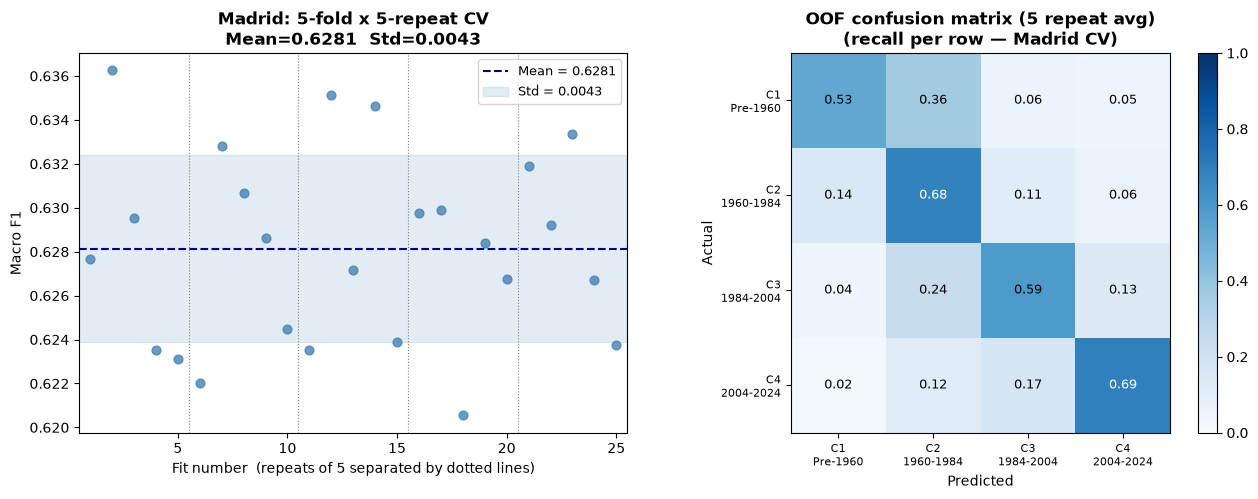

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: individual scores + mean/std band
ax   = axes[0]
xs   = np.arange(1, total_fits + 1)
mn   = np.mean(all_f1)
sd   = np.std(all_f1)

ax.scatter(xs, all_f1, color='steelblue', s=40, zorder=3, alpha=0.8)
ax.axhline(mn, color='navy', linewidth=1.5, linestyle='--', label=f'Mean = {mn:.4f}')
ax.fill_between([0.5, total_fits + 0.5], mn - sd, mn + sd,
                color='steelblue', alpha=0.15, label=f'Std = {sd:.4f}')

# Mark repeat boundaries
if N_REPEATS > 1:
    for r in range(1, N_REPEATS):
        ax.axvline(r * N_FOLDS + 0.5, color='grey', linewidth=0.8, linestyle=':')
    ax.set_xlabel(f'Fit number  (repeats of {N_FOLDS} separated by dotted lines)')
else:
    ax.set_xlabel('Fold')

ax.set_ylabel('Macro F1')
ax.set_title(f'Madrid: {N_FOLDS}-fold x {N_REPEATS}-repeat CV\n'
             f'Mean={mn:.4f}  Std={sd:.4f}', fontweight='bold')
ax.set_xlim(0.5, total_fits + 0.5)
ax.legend(fontsize=9)

# Right: out-of-fold confusion matrix (accumulated over all folds x repeats)
ax = axes[1]
classes_mad = sorted(np.unique(oof_true))
cm_oof  = confusion_matrix(oof_true, oof_pred, labels=classes_mad)
cm_norm = cm_oof.astype(float) / cm_oof.sum(axis=1, keepdims=True)
xlbls   = [f'C{c}\n{CLASS_LABELS_MADRID[c]}' for c in classes_mad]
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(classes_mad))); ax.set_xticklabels(xlbls, fontsize=8)
ax.set_yticks(range(len(classes_mad))); ax.set_yticklabels(xlbls, fontsize=8)
for i in range(len(classes_mad)):
    for j in range(len(classes_mad)):
        v = cm_norm[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                color='white' if v > 0.6 else 'black')
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
title_suffix = f'({N_REPEATS} repeat avg)' if N_REPEATS > 1 else ''
ax.set_title(f'OOF confusion matrix {title_suffix}\n(recall per row — Madrid CV)',
             fontweight='bold')
plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()


---

## 4.3a  Spatial Uncertainty Mapping

### `predict_proba` and per-pixel confidence

`RandomForestClassifier.predict_proba(X)` returns a **probability vector** $(p_1, p_2, p_3, p_4)$ for each pixel, where $p_k$ is the fraction of trees in the forest that voted for class $k$.  These values sum to 1, and the hard label produced by `predict()` is simply $\arg\max_k p_k$.

Using `predict_proba` gives a richer picture than a single label: a pixel with probabilities $(0.90, 0.05, 0.03, 0.02)$ is confidently assigned to class 1, while $(0.30, 0.28, 0.25, 0.17)$ is a near-random guess that happens to land on class 1.  The two pixels look identical in a confusion matrix but carry very different levels of certainty.

### Mapping uncertainty across the city

We use `predict_proba` to study the **geographical distribution of uncertainty** — where in the city is the model confident, and where is it unsure?  Mapping uncertainty back onto the building grid can reveal:

- Clusters of uncertain pixels along age-class boundaries or in mixed-use districts
- Areas where the domain gap (Madrid→Amsterdam) inflates uncertainty systematically
- Neighbourhoods where targeted labelling would most improve performance

Two complementary measures are shown for each city:

| Measure | Formula | Interpretation |
|---------|---------|----------------|
| **Shannon entropy** | $H = -\sum_k p_k \log_2 p_k$ (bits) | Ranges from 0 (all probability on one class) to 2 bits (uniform over 4 classes).  High = uncertain classifier. |
| **KL from true class** | $D = -\log_2 p_{\text{true}}$ (bits) | The KL divergence of the predicted distribution from the true one-hot distribution simplifies to the negative log-probability of the correct class.  **0 = model was certain and correct; high = wrong or uncertain.**  Colour scale is inverted so bright = accurate. |

In [26]:
import pickle
from pathlib import Path

data_path = Path(
    "/home/participant-b4/Building_Age_Classification/"
    "data/preprocessed/preprocessed_data.pkl"
)

with open(data_path, "rb") as f:
    saved_data = pickle.load(f)

pixel_ids_madrid = saved_data["pixel_ids_madrid"]
pixel_ids_amsterdam = saved_data["pixel_ids_amsterdam"]

print("Madrid:", pixel_ids_madrid.shape)
print("Amsterdam:", pixel_ids_amsterdam.shape)
print("Madrid coordinates sample:")
print(pixel_ids_madrid[:5])

Madrid: (76263, 2)
Amsterdam: (25992, 2)
Madrid coordinates sample:
[[ 14194 149671]
 [ 14196 149670]
 [ 14259 149645]
 [ 14268 149501]
 [ 14302 149354]]


In [25]:
import matplotlib.patches as mpatches

_GREY    = (0.6, 0.6, 0.6)
_NO_BLDG = mpatches.Patch(facecolor=_GREY, edgecolor='darkgrey', label='No building')


def make_pixel_grid(pixel_ids, values, fill_value):
    """Place per-pixel values into a 2-D spatial image using (px_key, py_key) coordinates.
    values: (N,) scalar or (N, C) multi-channel array.
    fill_value: value for grid positions with no building pixel.
    """
    px = pixel_ids[:, 0].astype(int);  px -= px.min()
    py = pixel_ids[:, 1].astype(int);  py -= py.min()
    H, W = py.max() + 1, px.max() + 1
    if values.ndim == 1:
        img = np.full((H, W), fill_value, dtype=np.float32)
        img[py, px] = values
    else:
        img = np.full((H, W, values.shape[1]), fill_value, dtype=np.float32)
        img[py, px] = values
    return img


def spatial_uncertainty_plots(pixel_ids, proba, y_true, title_prefix=''):
    """
    Set 1 (grey background):
        Left : RGB image where R=p2*256, G=p3*256, B=p4*256
        Right: actual class colours  (C1=black, C2=red, C3=green, C4=blue)
    Set 2 (hot_r — bright=good, dark=bad):
        Left : Shannon entropy in bits  (bright=certain, dark=uncertain)
        Right: KL(true||pred) = -log2(p_true_class)  (bright=accurate, dark=inaccurate)
    """
    eps = 1e-10

    # ── Set 1: colour images ──────────────────────────────────────────────────
    rgb_vals = (np.floor(proba[:, 1:] * 256).clip(0, 255) / 255.0).astype(np.float32)
    rgb_img  = make_pixel_grid(pixel_ids, rgb_vals, fill_value=0.70)

    _class_rgb = np.array([[0,0,0],[1,0,0],[0,1,0],[0,0,1]], dtype=np.float32)
    cls_img    = make_pixel_grid(pixel_ids, _class_rgb[y_true - 1], fill_value=0.7)

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    axes[0].imshow(rgb_img);  axes[0].axis('off')
    axes[0].set_title(f'{title_prefix}\nPredicted probabilities  '
                      r'(R=$p_2$, G=$p_3$, B=$p_4$)', fontsize=10)

    axes[1].imshow(cls_img);  axes[1].axis('off')
    axes[1].set_title(f'{title_prefix}\nActual classes', fontsize=10)
    axes[1].legend(handles=[
        mpatches.Patch(color='black', label='C1'),
        mpatches.Patch(color='red',   label='C2'),
        mpatches.Patch(color='green', label='C3'),
        mpatches.Patch(color='blue',  label='C4'),
        _NO_BLDG,
    ], loc='lower right', fontsize=8, framealpha=0.85)

    plt.suptitle('Set 1 — class colour maps  (grey = no building pixel)',
                 fontweight='bold')
    plt.tight_layout()
    plt.show()

    # ── Set 2: uncertainty / accuracy maps ────────────────────────────────────
    H_vals           = -(proba * np.log2(proba + eps)).sum(axis=1)
    true_class_proba = proba[np.arange(len(y_true)), y_true - 1]
    kl_vals          = -np.log2(true_class_proba + eps)

    H_img  = make_pixel_grid(pixel_ids, H_vals.astype(np.float32),  fill_value=np.nan)
    kl_img = make_pixel_grid(pixel_ids, kl_vals.astype(np.float32), fill_value=np.nan)

    cmap_h  = plt.cm.hot_r.copy(); cmap_h.set_bad(_GREY)
    cmap_kl = plt.cm.hot_r.copy(); cmap_kl.set_bad(_GREY)

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    im0 = axes[0].imshow(H_img, cmap=cmap_h, vmin=0, vmax=2)
    axes[0].axis('off')
    axes[0].set_title(f'{title_prefix}\nShannon entropy  '
                      '(bright=certain, dark=uncertain  |  max=2 bits)', fontsize=10)
    plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

    im1 = axes[1].imshow(kl_img, cmap=cmap_kl, vmin=0, vmax=2)
    axes[1].axis('off')
    axes[1].set_title(f'{title_prefix}\n'
                      r'KL from true class $= -\log_2 p_{\rm true}$ (bits)'
                      '\nbright=accurate, dark=inaccurate', fontsize=10)
    plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

    plt.suptitle('Set 2 — uncertainty & accuracy maps  '
                 '(grey=no building  |  bright=good, dark=bad)', fontweight='bold')
    plt.tight_layout()
    plt.show()


def spatial_accuracy_plots(pixel_ids, y_true, y_pred, title_prefix=''):
    """
    Plot 1: black=correct, red=incorrect.
    Plot 2: C1=black, C2=mid-dark red, C3=mid-dark green, C4=mid-dark blue, incorrect=yellow.
    Grey background on both.
    """
    correct = (y_true == y_pred)

    p1_vals = np.where(
        correct[:, None],
        np.array([[0, 0, 0]], dtype=np.float32),
        np.array([[1, 0, 0]], dtype=np.float32),
    )
    p1_img = make_pixel_grid(pixel_ids, p1_vals, fill_value=0.6)

    correct_colors = np.array([
        [  0,   0,   0],
        [140,   0,   0],
        [  0, 140,   0],
        [  0,   0, 140],
    ], dtype=np.float32) / 255.0
    yellow  = np.array([[1, 1, 0]], dtype=np.float32)
    p2_vals = np.where(correct[:, None], correct_colors[y_true - 1], yellow)
    p2_img  = make_pixel_grid(pixel_ids, p2_vals.astype(np.float32), fill_value=0.6)

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    axes[0].imshow(p1_img);  axes[0].axis('off')
    axes[0].set_title(f'{title_prefix}\nCorrect vs incorrect', fontsize=10)
    axes[0].legend(handles=[
        mpatches.Patch(color='black', label='Correct'),
        mpatches.Patch(color='red',   label='Incorrect'),
        _NO_BLDG,
    ], loc='lower right', fontsize=8, framealpha=0.85)

    axes[1].imshow(p2_img);  axes[1].axis('off')
    axes[1].set_title(f'{title_prefix}\nCorrect class  /  incorrect', fontsize=10)
    axes[1].legend(handles=[
        mpatches.Patch(color='black',                      label='C1 correct'),
        mpatches.Patch(color=(140/255, 0,       0      ),  label='C2 correct'),
        mpatches.Patch(color=(0,       140/255, 0      ),  label='C3 correct'),
        mpatches.Patch(color=(0,       0,       140/255),  label='C4 correct'),
        mpatches.Patch(color='yellow',                     label='Incorrect'),
        _NO_BLDG,
    ], loc='lower right', fontsize=8, framealpha=0.85)

    plt.suptitle('Correct / incorrect pixel maps  (grey = no building pixel)',
                 fontweight='bold')
    plt.tight_layout()
    plt.show()


# ── Madrid OOF ────────────────────────────────────────────────────────────────
pixel_ids_oof = pixel_ids_madrid[oof_indices]
spatial_uncertainty_plots(pixel_ids_oof, oof_proba, oof_true,
                          title_prefix='Madrid CV (out-of-fold)')
spatial_accuracy_plots(pixel_ids_oof, oof_true, oof_pred,
                       title_prefix='Madrid CV (out-of-fold)')


NameError: name 'pixel_ids_madrid' is not defined

We can see that despite the relatively low accuracy rates, the algorithm seems to be correctly identifying the major local areas where each class dominates. this suggests that a subsequent ML algorithm that acts on the soft-probabiliy output image may acheive improved accuracy.

Spatial plotting inputs verified.
Pixels: 76263
Probability columns: classes 1, 2, 3, 4
Predicted classes: [1 2 3 4]


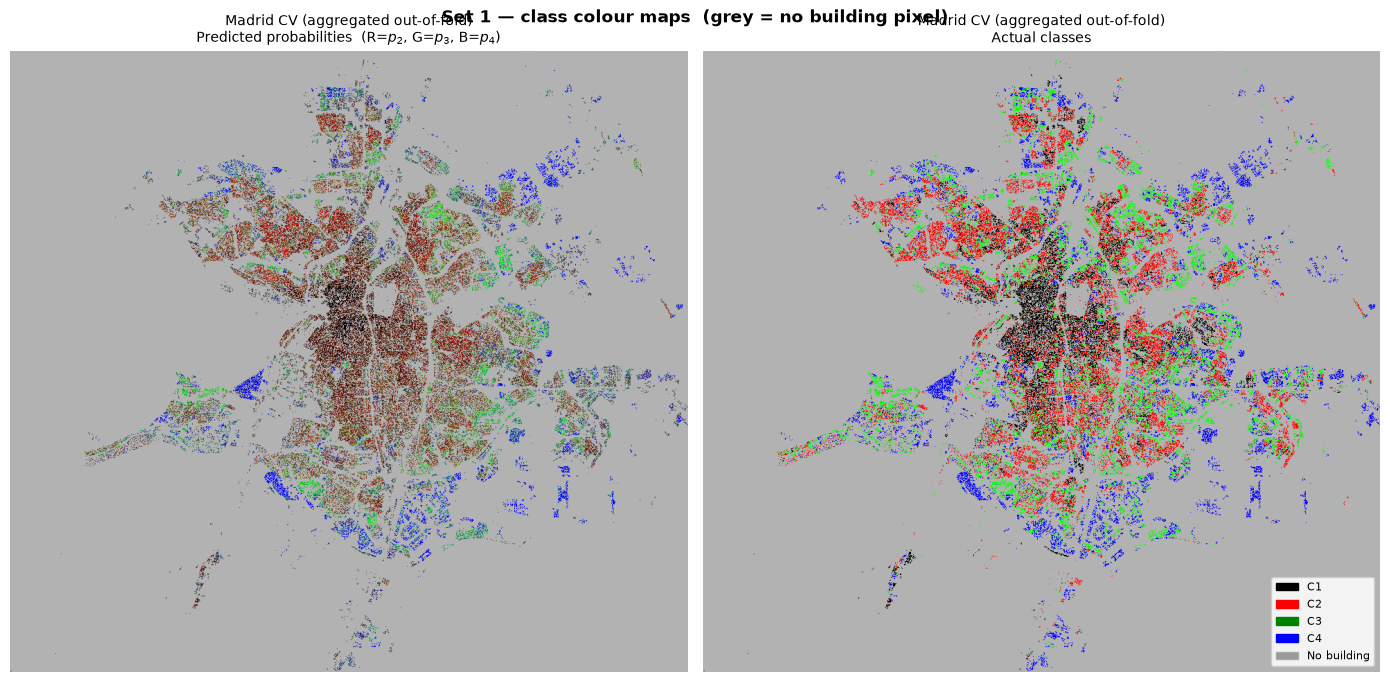

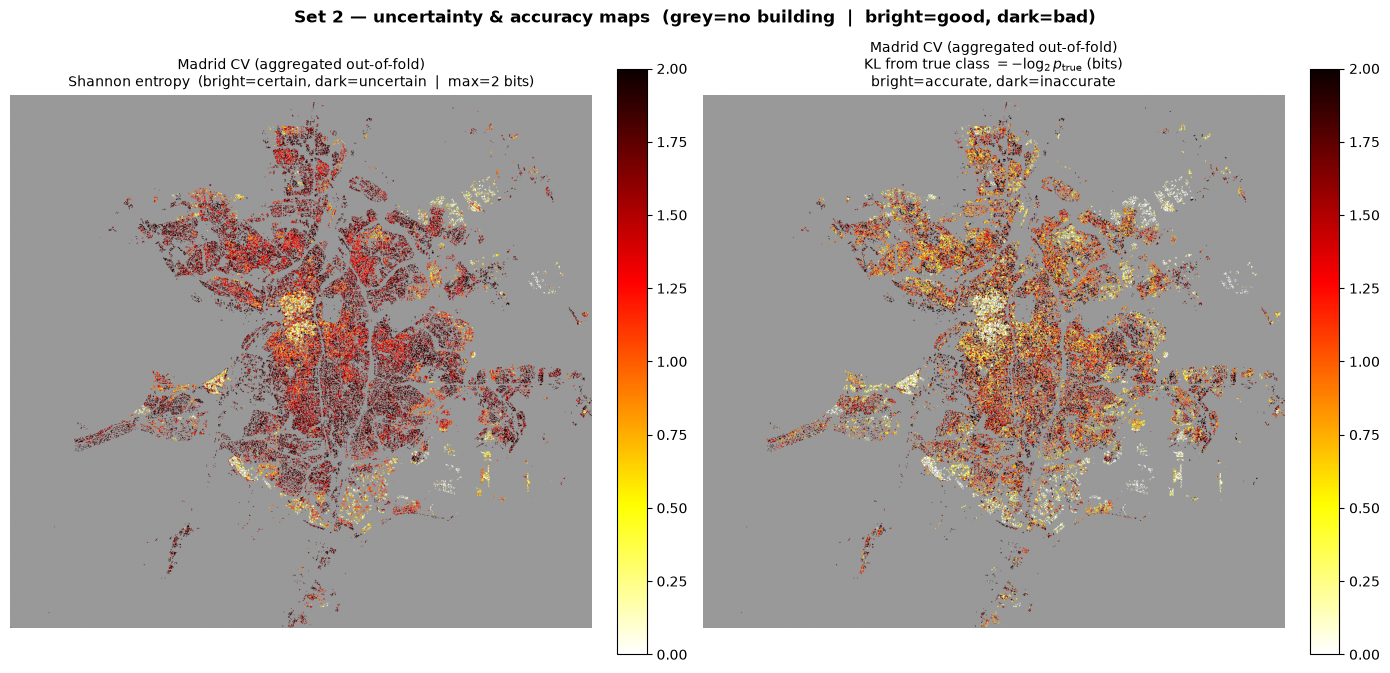

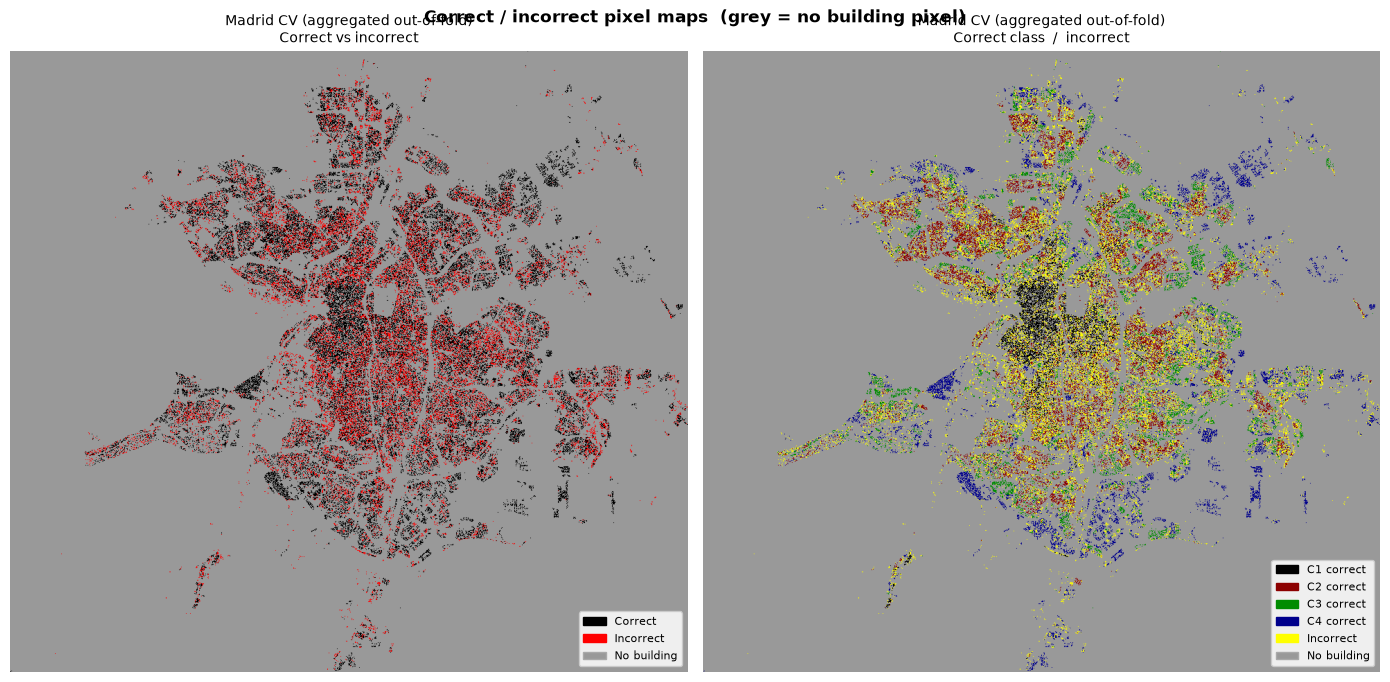

In [32]:
# One record per Madrid pixel
pixel_ids_oof = pixel_ids_madrid
oof_true_plot = oof_true_unique
oof_proba_plot = oof_proba_mean

# Convert zero-based probability-column indices to classes 1–4
oof_pred_plot = np.argmax(oof_proba_plot, axis=1) + 1

# Final alignment checks
assert len(pixel_ids_oof) == len(oof_true_plot) == len(oof_pred_plot)
assert oof_proba_plot.shape == (len(pixel_ids_oof), 4)
assert np.array_equal(np.unique(oof_true_plot), np.array([1, 2, 3, 4]))
assert np.array_equal(np.unique(oof_pred_plot), np.array([1, 2, 3, 4])) or set(
    np.unique(oof_pred_plot)
).issubset({1, 2, 3, 4})

print("Spatial plotting inputs verified.")
print("Pixels:", len(pixel_ids_oof))
print("Probability columns: classes 1, 2, 3, 4")
print("Predicted classes:", np.unique(oof_pred_plot))

# Generate spatial maps
spatial_uncertainty_plots(
    pixel_ids_oof,
    oof_proba_plot,
    oof_true_plot,
    title_prefix="Madrid CV (aggregated out-of-fold)"
)

spatial_accuracy_plots(
    pixel_ids_oof,
    oof_true_plot,
    oof_pred_plot,
    title_prefix="Madrid CV (aggregated out-of-fold)"
)



In [33]:
#calculate numerical results from the same aggregated OOF predictions
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("Aggregated Madrid OOF results")
print("------------------------------")

print("Accuracy:", accuracy_score(oof_true_plot, oof_pred_plot))
print("Macro-F1:", f1_score(
    oof_true_plot,
    oof_pred_plot,
    average="macro"
))

print("\nPer-class report:")
print(classification_report(
    oof_true_plot,
    oof_pred_plot,
    labels=[1, 2, 3, 4],
    target_names=[
        "Pre-1960",
        "1960-1984",
        "1984-2004",
        "2004-2024"
    ],
    digits=4,
    zero_division=0
))

print("\nConfusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(
    oof_true_plot,
    oof_pred_plot,
    labels=[1, 2, 3, 4]
))

Aggregated Madrid OOF results
------------------------------
Accuracy: 0.6367176743637151
Macro-F1: 0.6310235993596798

Per-class report:
              precision    recall  f1-score   support

    Pre-1960     0.6011    0.5325    0.5647     13794
   1960-1984     0.6192    0.6880    0.6518     27152
   1984-2004     0.6220    0.5895    0.6053     18672
   2004-2024     0.7124    0.6925    0.7023     16645

    accuracy                         0.6367     76263
   macro avg     0.6387    0.6256    0.6310     76263
weighted avg     0.6370    0.6367    0.6357     76263


Confusion matrix (rows=true, columns=predicted):
[[ 7345  4972   839   638]
 [ 3750 18680  3039  1683]
 [  783  4550 11007  2332]
 [  341  1968  2810 11526]]


In [29]:
#aggregate the OOF probabilities
import numpy as np

idx = np.asarray(oof_indices)
y_true_arr = np.asarray(oof_true)
proba_arr = np.asarray(oof_proba)

n_pixels = len(X_madrid)
n_classes = proba_arr.shape[1]

# Confirm each pixel has five OOF predictions
counts = np.bincount(idx, minlength=n_pixels)
assert np.all(counts == 5), "Unexpected OOF prediction counts"

# Check that repeated records agree on the true label
true_label_counts = np.zeros(n_pixels, dtype=int)
for pixel_idx in range(n_pixels):
    labels = y_true_arr[idx == pixel_idx]
    assert np.all(labels == labels[0]), (
        f"Inconsistent true labels for pixel index {pixel_idx}"
    )
    true_label_counts[pixel_idx] = labels[0]

# Aggregate predicted probabilities by original pixel index
proba_sum = np.zeros((n_pixels, n_classes), dtype=float)
np.add.at(proba_sum, idx, proba_arr)
oof_proba_mean = proba_sum / counts[:, None]

# One true label per pixel
oof_true_unique = true_label_counts

# Aggregate prediction: class with highest mean probability
oof_pred_mean = np.argmax(oof_proba_mean, axis=1)

# Check probability validity
assert np.allclose(oof_proba_mean.sum(axis=1), 1.0, atol=1e-5)

print("Aggregated probability shape:", oof_proba_mean.shape)
print("Unique true-label shape:", oof_true_unique.shape)
print("Aggregated prediction shape:", oof_pred_mean.shape)
print("All probabilities sum to 1:", np.allclose(
    oof_proba_mean.sum(axis=1), 1.0, atol=1e-5
))
print("Class labels in aggregated predictions:", np.unique(oof_pred_mean))

Aggregated probability shape: (76263, 4)
Unique true-label shape: (76263,)
Aggregated prediction shape: (76263,)
All probabilities sum to 1: True
Class labels in aggregated predictions: [0 1 2 3]


In [31]:
print("Madrid true labels:", np.unique(oof_true))
print("CLASS_LABELS_MADRID:", CLASS_LABELS_MADRID)

# Inspect the code that created oof_proba and oof_pred.
# If the fitted estimator is still available:
if "rf" in globals() and hasattr(rf, "classes_"):
    print("RF probability-column order:", rf.classes_)
else:
    print("RF class order not verified through a variable named 'rf'.")

Madrid true labels: [1 2 3 4]
CLASS_LABELS_MADRID: {1: 'Pre-1960', 2: '1960-1984', 3: '1984-2004', 4: '2004-2024'}
RF probability-column order: [1 2 3 4]


---

## 4.4 Final Model: Train on All Madrid Data

After cross-validation has confirmed the performance estimate, we train a final model on
the complete Madrid dataset. This maximises the information available and produces the
model used for Amsterdam transfer.

In this notebook we have not taken class imbalance into account.  When class imbalance is present, larger classes tend to be overpredicted, because a randomly-chosen datapoint has a larger probability of being in the larger class. in your model you may wish to take this into account.

**NOTE**: In this notebook, we use random forest as a baseline, with no parameter optimization. Your job is to improve on this baseline.  Be creative--try other techniques.

In [ ]:
print('Training final Random Forest on all Madrid data...')
rf_final = RandomForestClassifier(**RF_PARAMS)
rf_final.fit(X_madrid, y_madrid)
print('Done.')

# In-sample check (should be ~1.0; confirms the model is fitted)
y_mad_pred = rf_final.predict(X_madrid)
print(f'In-sample accuracy: {accuracy_score(y_madrid, y_mad_pred):.4f}  '
      f'(expected ~1.0 for RF with no max_depth limit)')


---

## 4.5 Feature Importance

Random Forest feature importance (mean decrease in impurity) shows which temporal
statistics are most useful for distinguishing age classes. Temporal features should
rank highly if the time-series approach is capturing meaningful signals.

In [ ]:
importances = rf_final.feature_importances_
sorted_idx  = np.argsort(importances)[::-1]

TOP_N = 20
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(range(TOP_N),
        importances[sorted_idx[:TOP_N]][::-1],
        color='steelblue', edgecolor='none')
ax.set_yticks(range(TOP_N))
ax.set_yticklabels([feature_names[i] for i in sorted_idx[:TOP_N]][::-1], fontsize=9)
ax.set_xlabel('Mean decrease in impurity')
ax.set_title(f'Top {TOP_N} features — Random Forest', fontweight='bold')
plt.tight_layout()
plt.show()

print('Top 10 features:')
for rank, idx in enumerate(sorted_idx[:10]):
    print(f'  {rank+1:2d}. {feature_names[idx]}: {importances[idx]:.4f}')


We see that a large number of features are nearly equal in importance. This is no doubt at least partially due to the high correlation between features.   But it also indicates that the Random Forest may be able to discern differencfes based on complex relationships, that would be difficult for a human to discern.

---

## 4.6 Zero-Shot Transfer to Amsterdam

We apply the Madrid-trained model to all Amsterdam pixels without using any Amsterdam labels.
This establishes the **baseline domain gap**: how much performance we lose when moving to
a city the model has never seen.

In [ ]:
y_ams_pred_zero = rf_final.predict(X_amsterdam)

f1_zero = f1_score(y_amsterdam, y_ams_pred_zero, average='macro')
print('Zero-shot transfer to Amsterdam (no Amsterdam labels):')
print(f'  Macro F1: {f1_zero:.4f}')
print()
classes_ams = sorted(np.unique(y_amsterdam))
print(classification_report(
    y_amsterdam, y_ams_pred_zero,
    labels=classes_ams,
    target_names=[f'Class {c}' for c in classes_ams],
    digits=4,
))


In [ ]:
cm_zero = confusion_matrix(y_amsterdam, y_ams_pred_zero,
                           labels=sorted(np.unique(y_amsterdam)))
cm_norm_zero = cm_zero.astype(float) / cm_zero.sum(axis=1, keepdims=True)
xlbls_ams = [f'C{c}\n{CLASS_LABELS_AMSTERDAM[c]}' for c in sorted(np.unique(y_amsterdam))]

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_norm_zero, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(xlbls_ams))); ax.set_xticklabels(xlbls_ams, fontsize=8)
ax.set_yticks(range(len(xlbls_ams))); ax.set_yticklabels(xlbls_ams, fontsize=8)
for i in range(len(xlbls_ams)):
    for j in range(len(xlbls_ams)):
        v = cm_norm_zero[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=10,
                color='white' if v > 0.6 else 'black')
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
ax.set_title(f'Zero-shot transfer — Amsterdam\nRecall per class  (macro F1={f1_zero:.3f})',
             fontweight='bold')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


Accuracy is poor for the zero-shot model.  this is to be expected, because buildings in Amsterdam have quite different characteristics from buildings in Madrid. The purpose of the few-shot retraining is to identify Amsterdam-specific clusters within the same metric space. The Amsterdam pixels are then assigned to these recalculated clusters. 

In [ ]:
# Amsterdam zero-shot — predict_proba from the Madrid-trained final model
proba_amsterdam_zero = rf_final.predict_proba(X_amsterdam)
spatial_uncertainty_plots(pixel_ids_amsterdam, proba_amsterdam_zero, y_amsterdam,
                          title_prefix='Amsterdam zero-shot')
spatial_accuracy_plots(pixel_ids_amsterdam, y_amsterdam, y_ams_pred_zero,
                       title_prefix='Amsterdam zero-shot')


In [19]:
y_ams_pred_zero = rf_final.predict(X_amsterdam)

f1_zero = f1_score(
    y_amsterdam,
    y_ams_pred_zero,
    average="macro"
)
print(f"  Macro F1: {f1_zero:.4f}")

NameError: name 'rf_final' is not defined

The graphs show clearly that Class 2 is being wildly overpredicted in the zero-shot model.

---

## 4.7 Few-Shot Prototype Transfer

The prototype classifier is the inference step of **prototype networks**, a standard
metric learning technique:

1. For each class, compute the **prototype** = mean feature vector of the labelled examples.
2. Classify unlabelled points by assigning them to the nearest prototype (Euclidean distance).

This is equivalent to 1-NN where the single "neighbour" is a smoothed class representative.
It generalises better than raw k-NN with very few labels because averaging reduces noise.

We run the experiment for several label budgets (samples per class) and repeat each
10 times with different random draws to estimate variance. The resulting plot shows
performance as a function of label budget — the key question for deciding how much
annotation effort Amsterdam requires.

In [ ]:
def prototype_predict(X_support, y_support, X_query):
    classes    = np.unique(y_support)
    prototypes = np.stack([X_support[y_support == c].mean(axis=0) for c in classes])
    dists      = np.linalg.norm(X_query[:, None, :] - prototypes[None, :, :], axis=2)
    return classes[dists.argmin(axis=1)]

SHOTS_PER_CLASS = [5, 10, 25, 50, 100, 200]
N_TRIALS        = 10
rng             = np.random.default_rng(42)
classes_ams     = np.unique(y_amsterdam)

proto_results = {n: [] for n in SHOTS_PER_CLASS}

for n_shots in SHOTS_PER_CLASS:
    for _ in range(N_TRIALS):
        support_idx = []
        for cls in classes_ams:
            cls_idx = np.where(y_amsterdam == cls)[0]
            chosen  = rng.choice(cls_idx,
                                 min(n_shots, len(cls_idx)),
                                 replace=False)
            support_idx.extend(chosen.tolist())

        support_idx = np.array(support_idx)
        query_mask  = np.ones(len(y_amsterdam), dtype=bool)
        query_mask[support_idx] = False

        y_pred = prototype_predict(
            X_amsterdam[support_idx], y_amsterdam[support_idx],
            X_amsterdam[query_mask]
        )
        f1 = f1_score(y_amsterdam[query_mask], y_pred,
                      average='macro', zero_division=0)
        proto_results[n_shots].append(f1)

    mn  = np.mean(proto_results[n_shots])
    std = np.std(proto_results[n_shots])
    print(f'  {n_shots:4d} shots/class: macro-F1 = {mn:.4f} +/- {std:.4f}')


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

ns    = SHOTS_PER_CLASS
means = [np.mean(proto_results[n]) for n in ns]
stds  = [np.std(proto_results[n])  for n in ns]

# Individual trial scatter
for n in ns:
    ax.scatter([n] * N_TRIALS, proto_results[n],
               color='#fd8d3c', alpha=0.35, s=20, zorder=3)

# Mean + error band
ax.errorbar(ns, means, yerr=stds, fmt='o-', color='#fd8d3c',
            linewidth=2, markersize=7, capsize=4,
            label='Prototype transfer (Amsterdam, mean +/- std)')

# Baselines
ax.axhline(f1_zero, color='steelblue', linestyle='--', linewidth=1.5,
           label=f'Zero-shot (no Amsterdam labels): {f1_zero:.3f}')
ax.axhline(np.mean(fold_f1), color='green', linestyle='--', linewidth=1.5,
           label=f'Madrid CV: {np.mean(fold_f1):.3f} +/- {np.std(fold_f1):.3f}')

ax.set_xlabel('Labeled Amsterdam examples per class')
ax.set_ylabel('Macro F1')
ax.set_xscale('log')
ax.set_title('Few-shot prototype transfer: Amsterdam F1 vs. label budget',
             fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()


The graph  shows that even with 5 examples per class, a huge boost in accuracy is seen compared to the zero-shot model. As few as 25 samples per class increases by an additional 10%, and 100 samples per class is sufficient to clearly establish the class centers, with additional samples bringing only marginal improvement.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
rng_cm = np.random.default_rng(42)

for ax, n_shots in zip(axes, [25, 100]):
    support_idx = []
    for cls in classes_ams:
        cls_idx = np.where(y_amsterdam == cls)[0]
        chosen  = rng_cm.choice(cls_idx, min(n_shots, len(cls_idx)), replace=False)
        support_idx.extend(chosen.tolist())

    support_idx = np.array(support_idx)
    query_mask  = np.ones(len(y_amsterdam), dtype=bool)
    query_mask[support_idx] = False

    y_pred_shot = prototype_predict(
        X_amsterdam[support_idx], y_amsterdam[support_idx],
        X_amsterdam[query_mask]
    )
    y_true_q = y_amsterdam[query_mask]

    cm_shot  = confusion_matrix(y_true_q, y_pred_shot, labels=classes_ams)
    cm_snorm = cm_shot.astype(float) / cm_shot.sum(axis=1, keepdims=True)
    f1_shot  = f1_score(y_true_q, y_pred_shot, average='macro', zero_division=0)

    im = ax.imshow(cm_snorm, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(xlbls_ams))); ax.set_xticklabels(xlbls_ams, fontsize=8)
    ax.set_yticks(range(len(xlbls_ams))); ax.set_yticklabels(xlbls_ams, fontsize=8)
    for i in range(len(xlbls_ams)):
        for j in range(len(xlbls_ams)):
            v = cm_snorm[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=10,
                    color='white' if v > 0.6 else 'black')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    ax.set_title(f'Prototype transfer: {n_shots} shots/class\n'
                 f'Amsterdam  (macro F1={f1_shot:.3f})', fontweight='bold')
    plt.colorbar(im, ax=ax)

plt.suptitle('Few-shot confusion matrices: recall per row', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


The recall performance for Amsterdam just about matches (and for some classes exceeds!) the recall obtained for Madrid.

In [ ]:
def prototype_predict_proba(X_support, y_support, X_query):
    """Soft class probabilities via softmax of negative L2 distances to prototypes."""
    classes    = np.unique(y_support)
    prototypes = np.stack([X_support[y_support == c].mean(axis=0) for c in classes])
    dists      = np.linalg.norm(X_query[:, None, :] - prototypes[None, :, :], axis=2)
    neg_d      = -dists
    neg_d     -= neg_d.max(axis=1, keepdims=True)
    exp_d      = np.exp(neg_d)
    return classes, exp_d / exp_d.sum(axis=1, keepdims=True)


# Reproduce the exact 25-shot split used in nb4-few-cm (same seed, same first 4 draws)
rng_25      = np.random.default_rng(42)
n_shots_25  = 25
support_idx_25 = []
for cls in classes_ams:
    cls_idx = np.where(y_amsterdam == cls)[0]
    chosen  = rng_25.choice(cls_idx, min(n_shots_25, len(cls_idx)), replace=False)
    support_idx_25.extend(chosen.tolist())
support_idx_25 = np.array(support_idx_25)
query_mask_25  = np.ones(len(y_amsterdam), dtype=bool)
query_mask_25[support_idx_25] = False

X_sup_25    = X_amsterdam[support_idx_25]
y_sup_25    = y_amsterdam[support_idx_25]
X_qry_25    = X_amsterdam[query_mask_25]
y_qry_25    = y_amsterdam[query_mask_25]
pids_qry_25 = pixel_ids_amsterdam[query_mask_25]

_, proba_25 = prototype_predict_proba(X_sup_25, y_sup_25, X_qry_25)
y_pred_25   = prototype_predict(X_sup_25, y_sup_25, X_qry_25)

spatial_uncertainty_plots(pids_qry_25, proba_25, y_qry_25,
                          title_prefix='Amsterdam 25-shot prototype (query pixels)')
spatial_accuracy_plots(pids_qry_25, y_qry_25, y_pred_25,
                       title_prefix='Amsterdam 25-shot prototype (query pixels)')


In [ ]:

from pathlib import Path

notebook = Path("3-Preprocessing.ipynb")

if not notebook.exists():
    print("Notebook not found:", notebook.resolve())
else:
    import json

    with notebook.open("r", encoding="utf-8") as f:
        nb = json.load(f)

    for i, cell in enumerate(nb["cells"]):
        if cell["cell_type"] != "code":
            continue

        source = "".join(cell["source"])
        keywords = [
            "weighted_mean_year",
            "pd.cut",
            "StandardScaler",
            "qa_valid",
            "interpol",
            "FEATURE",
            "coverage",
        ]

        if any(word.lower() in source.lower() for word in keywords):
            print(f"\n{'=' * 60}")
            print(f"CELL {i}")
            print(source[:7000])



As with Madrid, the model is identifying most local areas where each specific classes predominates. 

In [1]:


from pathlib import Path

root = Path.cwd()

print("Project files:")
for name in [
    "3-Preprocessing.ipynb",
    "4-Modelling.ipynb",
    "data",
    "data/preprocessed",
    "../data/preprocessed",
]:
    path = root / name
    print(f"{name}: exists={path.exists()}")

print("\nPreprocessed-data files anywhere under project:")
for path in root.glob("**/preprocessed_data.pkl"):
    print(path, f"{path.stat().st_size / 1024**2:.1f} MB")



Project files:
3-Preprocessing.ipynb: exists=True
4-Modelling.ipynb: exists=True
data: exists=True
data/preprocessed: exists=True
../data/preprocessed: exists=False

Preprocessed-data files anywhere under project:
/home/participant-b4/Building_Age_Classification/data/preprocessed/preprocessed_data.pkl 48.4 MB


In [4]:
from pathlib import Path
import pickle

data_path = (
    Path.cwd() / "data" / "preprocessed" / "preprocessed_data.pkl"
)

print("Loading from:", data_path)
print("File exists:", data_path.exists())

with open(data_path, "rb") as f:
    data = pickle.load(f)

X_madrid = data["X_madrid"]
X_amsterdam = data["X_amsterdam"]
y_madrid = data["y_madrid"]
y_amsterdam = data["y_amsterdam"]
FEATURE_COLS = data["feature_names"]
pixel_ids_madrid = data["pixel_ids_madrid"]
pixel_ids_amsterdam = data["pixel_ids_amsterdam"]

print("Madrid:", X_madrid.shape, y_madrid.shape)
print("Amsterdam:", X_amsterdam.shape, y_amsterdam.shape)

Loading from: /home/participant-b4/Building_Age_Classification/data/preprocessed/preprocessed_data.pkl
File exists: True
Madrid: (76263, 60) (76263,)
Amsterdam: (25992, 60) (25992,)


In [3]:
print("Keys in preprocessed_data.pkl:")
for key in data.keys():
    print(f"{key}: {type(data[key]).__name__}")
    

Keys in preprocessed_data.pkl:
X_madrid: ndarray
y_madrid: ndarray
X_amsterdam: ndarray
y_amsterdam: ndarray
feature_names: list
scaler: StandardScaler
pixel_ids_madrid: ndarray
pixel_ids_amsterdam: ndarray
feat_groups: dict


In [6]:
import inspect

print(inspect.getsource(type(data["scaler"])))
print("\nFeature groups:", list(data["feat_groups"].keys()))

class StandardScaler(
    CallbackSupportMixin, OneToOneFeatureMixin, TransformerMixin, BaseEstimator
):
    """Standardize features by removing the mean and scaling to unit variance.

    The standard score of a sample `x` is calculated as:

    .. code-block:: text

        z = (x - u) / s

    where `u` is the mean of the training samples or zero if `with_mean=False`,
    and `s` is the standard deviation of the training samples or one if
    `with_std=False`.

    Centering and scaling happen independently on each feature by computing
    the relevant statistics on the samples in the training set. Mean and
    standard deviation are then stored to be used on later data using
    :meth:`transform`.

    Standardization of a dataset is a common requirement for many
    machine learning estimators: they might behave badly if the
    individual features do not more or less look like standard normally
    distributed data (e.g. Gaussian with 0 mean and unit variance).

    For instance 

In [7]:

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.metrics.pairwise import euclidean_distances

# Fixed experiment protocol
SEED = 42
BUDGETS = [5, 25, 50, 100, 200]
REPEATS = 20
CLASSES = np.array([1, 2, 3, 4])
SOURCE_WEIGHT = 0.5

X_source = np.asarray(X_madrid, dtype=np.float64)
y_source = np.asarray(y_madrid).ravel()
X_target = np.asarray(X_amsterdam, dtype=np.float64)
y_target = np.asarray(y_amsterdam).ravel()

# Sanity checks before fitting
assert X_source.shape[1] == X_target.shape[1]
assert set(np.unique(y_source)) == set(CLASSES)
assert set(np.unique(y_target)) == set(CLASSES)
assert np.isfinite(X_source).all()
assert np.isfinite(X_target).all()

# Fit the source model once, using Madrid only
print("Training Madrid source model...")
start = time.time()

source_model = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)
source_model.fit(X_source, y_source)

assert np.array_equal(source_model.classes_, CLASSES)

print(f"Source model fitted in {time.time() - start:.1f}s")

# Evaluate all methods on identical support/query splits
rng = np.random.default_rng(SEED)
records = []

for budget in BUDGETS:
    print(f"\nBudget: {budget} labeled pixels per class")

    class_indices = {
        cls: np.flatnonzero(y_target == cls)
        for cls in CLASSES
    }

    if any(len(class_indices[c]) < budget for c in CLASSES):
        raise ValueError("Insufficient target samples for a budget.")

    for repeat in range(REPEATS):
        support_indices = np.concatenate([
            rng.choice(class_indices[cls], size=budget, replace=False)
            for cls in CLASSES
        ])

        support_mask = np.zeros(len(y_target), dtype=bool)
        support_mask[support_indices] = True
        query_indices = np.flatnonzero(~support_mask)

        X_support = X_target[support_indices]
        y_support = y_target[support_indices]
        X_query = X_target[query_indices]
        y_query = y_target[query_indices]

        # Method 1: Madrid-trained RF, no target adaptation
        source_proba = source_model.predict_proba(X_query)
        pred_source = source_model.classes_[source_proba.argmax(axis=1)]

        # Method 2: nearest class prototype from target support
        prototypes = np.vstack([
            X_support[y_support == cls].mean(axis=0)
            for cls in CLASSES
        ])
        distances = euclidean_distances(X_query, prototypes)
        pred_proto = CLASSES[distances.argmin(axis=1)]

        # Method 3: RF trained only on the target support sample
        target_model = RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=SEED + repeat,
            n_jobs=-1,
        )
        target_model.fit(X_support, y_support)

        target_proba = target_model.predict_proba(X_query)
        pred_target = target_model.classes_[target_proba.argmax(axis=1)]

        # Method 4: fixed 50/50 probability blend
        # Align probability columns by class label before combining.
        target_proba_aligned = np.zeros_like(source_proba)

        for j, cls in enumerate(target_model.classes_):
            source_j = np.flatnonzero(source_model.classes_ == cls)[0]
            target_proba_aligned[:, source_j] = target_proba[:, j]

        blended_proba = (
            SOURCE_WEIGHT * source_proba
            + (1 - SOURCE_WEIGHT) * target_proba_aligned
        )
        pred_blended = source_model.classes_[blended_proba.argmax(axis=1)]

        predictions = {
            "Madrid_RF_zero_shot": pred_source,
            "Amsterdam_prototype": pred_proto,
            "Amsterdam_RF_only": pred_target,
            "Madrid_Amsterdam_RF_blend_50_50": pred_blended,
        }

        for method, pred in predictions.items():
            score = f1_score(
                y_query,
                pred,
                labels=CLASSES,
                average="macro",
                zero_division=0,
            )

            records.append({
                "budget_per_class": budget,
                "repeat": repeat,
                "seed": SEED,
                "method": method,
                "macro_f1": score,
                "n_support": len(support_indices),
                "n_query": len(query_indices),
            })

    print(f"Completed {REPEATS} repetitions.")

# Summarize measured results
experiment_df = pd.DataFrame(records)

summary_df = (
    experiment_df
    .groupby(["budget_per_class", "method"])["macro_f1"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={"mean": "mean_macro_f1", "std": "std_macro_f1"})
)

print("\nFEW-SHOT TRANSFER RESULTS")
print(summary_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Save to a new file; leave existing experiment files untouched.
output_path = "fewshot_transfer_experiment_A.csv"
experiment_df.to_csv(output_path, index=False)

summary_path = "fewshot_transfer_experiment_A_summary.csv"
summary_df.to_csv(summary_path, index=False)

print(f"\nSaved raw results: {output_path}")
print(f"Saved summary: {summary_path}")


Training Madrid source model...
Source model fitted in 44.9s

Budget: 5 labeled pixels per class
Completed 20 repetitions.

Budget: 25 labeled pixels per class
Completed 20 repetitions.

Budget: 50 labeled pixels per class
Completed 20 repetitions.

Budget: 100 labeled pixels per class
Completed 20 repetitions.

Budget: 200 labeled pixels per class
Completed 20 repetitions.

FEW-SHOT TRANSFER RESULTS
 budget_per_class                          method  mean_macro_f1  std_macro_f1
                5               Amsterdam_RF_only         0.5595        0.0437
                5             Amsterdam_prototype         0.5432        0.0426
                5 Madrid_Amsterdam_RF_blend_50_50         0.5853        0.0313
                5             Madrid_RF_zero_shot         0.4433        0.0001
               25               Amsterdam_RF_only         0.6330        0.0192
               25             Amsterdam_prototype         0.5975        0.0210
               25 Madrid_Amsterdam_RF_blend

In [8]:

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# Requires X_madrid, y_madrid, X_amsterdam, y_amsterdam
# to already be loaded from preprocessed_data.pkl.

SEED = 42
BUDGETS = [5, 25, 50, 100, 200]
REPEATS = 20
WEIGHTS = [0.25, 0.50, 0.75]  # fraction of Madrid RF probabilities

# Stage 1: train source model on Madrid only.
source_rf = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)
source_rf.fit(X_madrid, y_madrid)

classes = np.array([1, 2, 3, 4])
rng = np.random.default_rng(SEED)
rows = []

for budget in BUDGETS:
    for repeat in range(REPEATS):
        support_idx, query_idx = [], []

        # Draw the same support/query split for every blend weight.
        for cls in classes:
            cls_idx = np.flatnonzero(y_amsterdam == cls)
            shuffled = rng.permutation(cls_idx)

            support_idx.extend(shuffled[:budget])
            query_idx.extend(shuffled[budget:])

        support_idx = np.asarray(support_idx)
        query_idx = np.asarray(query_idx)

        target_rf = RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=SEED + repeat,
            n_jobs=-1
        )
        target_rf.fit(
            X_amsterdam[support_idx],
            y_amsterdam[support_idx]
        )

        X_query = X_amsterdam[query_idx]
        y_query = y_amsterdam[query_idx]

        # Align probability columns to class labels before blending.
        p_source_raw = source_rf.predict_proba(X_query)
        p_target_raw = target_rf.predict_proba(X_query)

        p_source = np.zeros((len(query_idx), len(classes)))
        p_target = np.zeros_like(p_source)

        for j, cls in enumerate(source_rf.classes_):
            p_source[:, np.where(classes == cls)[0][0]] = p_source_raw[:, j]

        for j, cls in enumerate(target_rf.classes_):
            p_target[:, np.where(classes == cls)[0][0]] = p_target_raw[:, j]

        for madrid_weight in WEIGHTS:
            p_blend = (
                madrid_weight * p_source
                + (1 - madrid_weight) * p_target
            )
            y_pred = classes[np.argmax(p_blend, axis=1)]

            rows.append({
                "budget_per_class": budget,
                "repeat": repeat,
                "madrid_weight": madrid_weight,
                "amsterdam_weight": 1 - madrid_weight,
                "macro_f1": f1_score(
                    y_query, y_pred,
                    labels=classes,
                    average="macro",
                    zero_division=0
                )
            })

raw = pd.DataFrame(rows)
raw.to_csv("fewshot_transfer_experiment_B.csv", index=False)

summary = (
    raw.groupby(["budget_per_class", "madrid_weight", "amsterdam_weight"])
       ["macro_f1"]
       .agg(["mean", "std"])
       .reset_index()
)
summary.to_csv("fewshot_transfer_experiment_B_summary.csv", index=False)

display(summary.sort_values(
    ["budget_per_class", "mean"],
    ascending=[True, False]
).round(4))


,budget_per_class,madrid_weight,amsterdam_weight,mean,std
1,5,0.50,0.50,0.5962,0.0185
0,5,0.25,0.75,0.5825,0.0220
2,5,0.75,0.25,0.5613,0.0176
4,25,0.50,0.50,0.6480,0.0110
3,25,0.25,0.75,0.6425,0.0130
5,25,0.75,0.25,0.6106,0.0085
7,50,0.50,0.50,0.6665,0.0056
6,50,0.25,0.75,0.6657,0.0075
8,50,0.75,0.25,0.6264,0.0055
9,100,0.25,0.75,0.6798,0.0091


In [9]:

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.utils.validation import check_is_fitted
import time

# Experiment C: refine Madrid/Amsterdam probability blend
SEED = 42
BUDGETS = [5, 25, 50, 100, 200]
REPEATS = 20
MADRID_WEIGHTS = [0.10, 0.20, 0.25, 0.30, 0.40, 0.50]
CLASSES = np.array([1, 2, 3, 4])

start_time = time.time()

# Basic input checks
assert X_madrid.shape[1] == X_amsterdam.shape[1], (
    "Madrid and Amsterdam feature counts differ."
)
assert len(X_madrid) == len(y_madrid)
assert len(X_amsterdam) == len(y_amsterdam)
assert set(np.unique(y_madrid)) == set(CLASSES)
assert set(np.unique(y_amsterdam)) == set(CLASSES)
assert np.isfinite(X_madrid).all()
assert np.isfinite(X_amsterdam).all()

# Fit source model once
source_rf = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)
source_rf.fit(X_madrid, y_madrid)

# Map probability columns to class order [1, 2, 3, 4]
def align_probabilities(model, X):
    raw = model.predict_proba(X)
    aligned = np.zeros((len(X), len(CLASSES)))
    for j, cls in enumerate(model.classes_):
        aligned[:, np.where(CLASSES == cls)[0][0]] = raw[:, j]
    return aligned

results = []
rng = np.random.default_rng(SEED)

for budget in BUDGETS:
    print(f"Running budget: {budget} samples per class")

    for repeat in range(REPEATS):
        support_idx = []
        query_idx = []

        # Make one split, shared by every weight in this repetition
        for cls in CLASSES:
            cls_idx = np.flatnonzero(y_amsterdam == cls)
            shuffled = rng.permutation(cls_idx)

            if len(shuffled) <= budget:
                raise ValueError(
                    f"Class {cls} has too few samples for budget {budget}."
                )

            support_idx.extend(shuffled[:budget])
            query_idx.extend(shuffled[budget:])

        support_idx = np.asarray(support_idx)
        query_idx = np.asarray(query_idx)

        X_support = X_amsterdam[support_idx]
        y_support = y_amsterdam[support_idx]
        X_query = X_amsterdam[query_idx]
        y_query = y_amsterdam[query_idx]

        # Fit target model once for this support set
        target_rf = RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=SEED + repeat,
            n_jobs=-1
        )
        target_rf.fit(X_support, y_support)

        p_madrid = align_probabilities(source_rf, X_query)
        p_amsterdam = align_probabilities(target_rf, X_query)

        for madrid_weight in MADRID_WEIGHTS:
            p_blend = (
                madrid_weight * p_madrid
                + (1 - madrid_weight) * p_amsterdam
            )
            predictions = CLASSES[np.argmax(p_blend, axis=1)]

            score = f1_score(
                y_query,
                predictions,
                labels=CLASSES,
                average="macro",
                zero_division=0
            )

            results.append({
                "experiment": "C",
                "budget_per_class": budget,
                "repeat": repeat + 1,
                "madrid_weight": madrid_weight,
                "amsterdam_weight": 1 - madrid_weight,
                "macro_f1": score
            })

results_df = pd.DataFrame(results)

summary_df = (
    results_df
    .groupby(
        ["budget_per_class", "madrid_weight", "amsterdam_weight"],
        as_index=False
    )
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        repetitions=("macro_f1", "count")
    )
    .sort_values(
        ["budget_per_class", "mean_macro_f1"],
        ascending=[True, False]
    )
)

results_df.to_csv("fewshot_transfer_experiment_C.csv", index=False)
summary_df.to_csv(
    "fewshot_transfer_experiment_C_summary.csv",
    index=False
)

print("\nEXPERIMENT C SUMMARY")
print(summary_df.round(4).to_string(index=False))

print(f"\nRuntime: {(time.time() - start_time) / 60:.2f} minutes")
print("\nSaved:")
print("- fewshot_transfer_experiment_C.csv")
print("- fewshot_transfer_experiment_C_summary.csv")


Running budget: 5 samples per class
Running budget: 25 samples per class
Running budget: 50 samples per class
Running budget: 100 samples per class
Running budget: 200 samples per class

EXPERIMENT C SUMMARY
 budget_per_class  madrid_weight  amsterdam_weight  mean_macro_f1  std_macro_f1  repetitions
                5           0.50              0.50         0.5962        0.0185           20
                5           0.40              0.60         0.5933        0.0190           20
                5           0.30              0.70         0.5866        0.0209           20
                5           0.25              0.75         0.5825        0.0220           20
                5           0.20              0.80         0.5784        0.0233           20
                5           0.10              0.90         0.5701        0.0259           20
               25           0.50              0.50         0.6480        0.0110           20
               25           0.40              0.

In [10]:

# FE-01: Test five additional early-to-late spectral-index changes
# Run after Notebook 3, cell 46 has created the FE-01 feature tables.

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score

FEATURE_COLS_FE01 = FEATURE_COLS + INDEX_CHANGE_COLS

# Build both feature matrices from the same raw feature tables.
# Random Forest does not require standardisation.
experiments = {
    "baseline_60": (
        features_madrid[FEATURE_COLS].to_numpy(dtype=np.float64),
        features_amsterdam[FEATURE_COLS].to_numpy(dtype=np.float64),
    ),
    "FE01_65": (
        features_madrid_fe01[FEATURE_COLS_FE01].to_numpy(dtype=np.float64),
        features_amsterdam_fe01[FEATURE_COLS_FE01].to_numpy(dtype=np.float64),
    ),
}

# Check labels and missing values before training.
y_src = features_madrid["age_class"].to_numpy(dtype=int)
y_tgt = features_amsterdam["age_class"].to_numpy(dtype=int)

for name, (X_src, X_tgt) in experiments.items():
    assert len(X_src) == len(y_src), f"{name}: Madrid row mismatch"
    assert len(X_tgt) == len(y_tgt), f"{name}: Amsterdam row mismatch"
    if not np.isfinite(X_src).all() or not np.isfinite(X_tgt).all():
        raise ValueError(f"{name}: non-finite feature values found")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, (X_src, X_tgt) in experiments.items():
    model = RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )

    start = time.time()

    scores = cross_val_score(
        model, X_src, y_src,
        cv=cv, scoring="f1_macro", n_jobs=1
    )

    model.fit(X_src, y_src)
    target_pred = model.predict(X_tgt)
    target_f1 = f1_score(
        y_tgt, target_pred,
        labels=[1, 2, 3, 4],
        average="macro",
        zero_division=0,
    )

    results.append({
        "experiment": name,
        "n_features": X_src.shape[1],
        "Madrid_CV_mean_F1": scores.mean(),
        "Madrid_CV_std_F1": scores.std(),
        "Amsterdam_zero_shot_F1": target_f1,
        "runtime_min": (time.time() - start) / 60,
    })

comparison = pd.DataFrame(results)
print(comparison.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

comparison.to_csv("FE01_index_change_comparison.csv", index=False)
print("\nSaved: FE01_index_change_comparison.csv")


NameError: name 'INDEX_CHANGE_COLS' is not defined

In [11]:
# Define the five additional spectral-index change features
INDEX_CHANGE_COLS = [
    f"d_{idx}" for idx in INDEX_COLS
]

# Confirm the feature names
print("New features:", INDEX_CHANGE_COLS)
print("Number of new features:", len(INDEX_CHANGE_COLS))

NameError: name 'INDEX_COLS' is not defined

In [12]:
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score

y_madrid = madrid_baseline_clean["age_class"].to_numpy(dtype=int)
y_amsterdam = amsterdam_baseline_clean["age_class"].to_numpy(dtype=int)

experiments = [
    (
        "Baseline_60",
        madrid_baseline_clean[FEATURE_COLS].to_numpy(dtype=float),
        amsterdam_baseline_clean[FEATURE_COLS].to_numpy(dtype=float),
    ),
    (
        "FE01_65",
        madrid_eval_clean[FEATURE_COLS_FE01].to_numpy(dtype=float),
        amsterdam_eval_clean[FEATURE_COLS_FE01].to_numpy(dtype=float),
    ),
]

# Verify that the target rows and labels align.
assert np.array_equal(
    madrid_baseline_clean[["px_key", "py_key"]].to_numpy(),
    madrid_eval_clean[["px_key", "py_key"]].to_numpy(),
)
assert np.array_equal(
    amsterdam_baseline_clean[["px_key", "py_key"]].to_numpy(),
    amsterdam_eval_clean[["px_key", "py_key"]].to_numpy(),
)
assert np.array_equal(
    y_amsterdam,
    amsterdam_eval_clean["age_class"].to_numpy(dtype=int),
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, X_src, X_tgt in experiments:
    model = RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    )

    start = time.time()

    cv_scores = cross_val_score(
        model, X_src, y_madrid,
        cv=cv, scoring="f1_macro", n_jobs=1
    )

    model.fit(X_src, y_madrid)
    predictions = model.predict(X_tgt)

    target_f1 = f1_score(
        y_amsterdam,
        predictions,
        labels=[1, 2, 3, 4],
        average="macro",
        zero_division=0,
    )

    results.append({
        "experiment": name,
        "features": X_src.shape[1],
        "Madrid_CV_mean_F1": cv_scores.mean(),
        "Madrid_CV_std_F1": cv_scores.std(),
        "Amsterdam_zero_shot_F1": target_f1,
        "runtime_min": (time.time() - start) / 60,
    })

comparison_fe01 = pd.DataFrame(results)

print(comparison_fe01.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

comparison_fe01.to_csv(
    "FE01_matched_comparison.csv", index=False
)
print("\nSaved FE01_matched_comparison.csv")

NameError: name 'madrid_baseline_clean' is not defined

NameError: name 'add_index_change_features' is not defined

In [14]:
import numpy as np

for name, X in [
    ("Madrid", X_madrid),
    ("Amsterdam", X_amsterdam),
]:
    print(
        name,
        "shape:", X.shape,
        "NaNs:", np.isnan(X).sum(),
        "infinities:", np.isinf(X).sum(),
    )

Madrid shape: (76263, 60) NaNs: 0 infinities: 0
Amsterdam shape: (25992, 60) NaNs: 0 infinities: 0


In [17]:
# Inspect the baseline evaluation variables available in this notebook
for name in [
    "cv_scores",
    "cv_f1_scores",
    "baseline_model",
    "rf_model",
    "model",
]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: {type(value).__name__}")
        if hasattr(value, "shape"):
            print("  shape:", value.shape)
        elif isinstance(value, (list, tuple)):
            print("  length:", len(value))

In [18]:
print("Modelling notebook is running.")
print("X_madrid:", X_madrid.shape)
print("y_madrid:", y_madrid.shape)
print("X_amsterdam:", X_amsterdam.shape)
print("y_amsterdam:", y_amsterdam.shape)

Modelling notebook is running.
X_madrid: (76263, 60)
y_madrid: (76263,)
X_amsterdam: (25992, 60)
y_amsterdam: (25992,)


In [20]:
from sklearn.ensemble import RandomForestClassifier

for name, value in list(globals().items()):
    if isinstance(value, RandomForestClassifier):
        print(
            name,
            "| fitted:",
            hasattr(value, "estimators_"),
            "| trees:",
            len(value.estimators_) if hasattr(value, "estimators_") else 0
        )

source_model | fitted: True | trees: 500
target_model | fitted: True | trees: 300
source_rf | fitted: True | trees: 500
target_rf | fitted: True | trees: 300


In [24]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_ams_pred_zero = source_model.predict(X_amsterdam)

print(classification_report(
    y_amsterdam,
    y_ams_pred_zero,
    labels=[1, 2, 3, 4],
    target_names=[f"Class {c}" for c in [1, 2, 3, 4]],
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    y_amsterdam,
    y_ams_pred_zero,
    labels=[1, 2, 3, 4]
))

              precision    recall  f1-score   support

     Class 1     0.4635    0.4223    0.4420      7568
     Class 2     0.3862    0.6489    0.4843      8802
     Class 3     0.7741    0.1870    0.3012      6745
     Class 4     0.5659    0.5269    0.5457      2877

    accuracy                         0.4496     25992
   macro avg     0.5474    0.4463    0.4433     25992
weighted avg     0.5293    0.4496    0.4312     25992

Confusion matrix:
[[3196 4207   47  118]
 [2527 5712  172  391]
 [ 921 3909 1261  654]
 [ 251  961  149 1516]]


In [28]:
import pandas as pd
from pathlib import Path

path = Path("data/preprocessed/prototype_scaling_experiments.csv")
scaling_results = pd.read_csv(path)

print("Loaded results:", path)
print("Rows:", len(scaling_results))
print()
print(scaling_results.to_string(index=False))

Loaded results: data/preprocessed/prototype_scaling_experiments.csv
Rows: 15

 budget_per_class  scaling  mean_macro_f1  std_macro_f1  repeats
                5      raw       0.507649      0.054013       20
                5 standard       0.508431      0.052596       20
                5   robust       0.491820      0.048609       20
               25      raw       0.596050      0.020208       20
               25 standard       0.596919      0.018303       20
               25   robust       0.595366      0.018931       20
               50      raw       0.607787      0.008952       20
               50 standard       0.603858      0.009906       20
               50   robust       0.595524      0.014487       20
              100      raw       0.615155      0.007809       20
              100 standard       0.612757      0.010926       20
              100   robust       0.607520      0.012338       20
              200      raw       0.615342      0.004657       20
            

In [29]:
from pathlib import Path
import pandas as pd
import numpy as np

root = Path.cwd()
matches = []

for path in root.rglob("*.csv"):
    try:
        df = pd.read_csv(path)
        numeric = df.select_dtypes(include="number")

        for col in numeric.columns:
            values = numeric[col].dropna()
            close = values[np.isclose(values, 0.699, atol=0.002)]

            if not close.empty:
                matches.append({
                    "file": str(path.relative_to(root)),
                    "column": col,
                    "values": close.tolist()[:10],
                })
    except Exception:
        continue

if matches:
    for match in matches:
        print(match)
else:
    print("No CSV value near 0.699 found under:", root)

{'file': 'fewshot_transfer_experiment_B.csv', 'column': 'macro_f1', 'values': [0.7009090522693767, 0.6984749518894376, 0.6983554837985317, 0.7005994313489208, 0.697423562926917, 0.6987896004117526, 0.6977652053640727]}
{'file': 'fewshot_transfer_experiment_C.csv', 'column': 'amsterdam_weight', 'values': [0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7, 0.7]}
{'file': 'fewshot_transfer_experiment_C.csv', 'column': 'macro_f1', 'values': [0.6977248901436148, 0.6999318641411175, 0.7009090522693767, 0.6995224941895846, 0.6984749518894376, 0.6987748739704011, 0.6992672051968437, 0.6983554837985317, 0.6976201358116499, 0.6990582285913044]}
{'file': 'fewshot_transfer_experiment_C_summary.csv', 'column': 'amsterdam_weight', 'values': [0.7, 0.7, 0.7, 0.7, 0.7]}
{'file': 'fewshot_transfer_experiment_A.csv', 'column': 'macro_f1', 'values': [0.7004661838181232, 0.6981898290775851, 0.6998809160198598]}
{'file': 'data/preprocessed/target_rf_tuning.csv', 'column': 'macro_f1', 'values': [0.697321433813367,

In [31]:
import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

SEED = 42
BUDGETS = [5, 25, 50, 100, 200]
REPEATS = 20
MADRID_WEIGHTS = [0.20, 0.25, 0.30, 0.35, 0.40]
LEAF_SIZES = [1, 2, 5, 10]

CLASSES = np.array([1, 2, 3, 4])

X_source = np.asarray(X_madrid)
y_source = np.asarray(y_madrid).ravel()
X_target = np.asarray(X_amsterdam)
y_target = np.asarray(y_amsterdam).ravel()

assert X_source.shape[1] == X_target.shape[1]
assert np.isfinite(X_source).all()
assert np.isfinite(X_target).all()

# Train the Madrid model once.
source_model = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
)
source_model.fit(X_source, y_source)

def aligned_proba(model, X):
    raw = model.predict_proba(X)
    aligned = np.zeros((len(X), len(CLASSES)))

    for j, cls in enumerate(model.classes_):
        aligned[:, np.where(CLASSES == cls)[0][0]] = raw[:, j]

    return aligned

# Precompute target indices by class.
class_indices = {
    cls: np.flatnonzero(y_target == cls)
    for cls in CLASSES
}

rng = np.random.default_rng(SEED)
records = []
start = time.time()

for budget in BUDGETS:
    for repeat in range(REPEATS):

        # Same support/query split for every leaf size and blend weight.
        support = np.concatenate([
            rng.choice(class_indices[c], budget, replace=False)
            for c in CLASSES
        ])

        support_mask = np.zeros(len(y_target), dtype=bool)
        support_mask[support] = True
        query = np.flatnonzero(~support_mask)

        X_support, y_support = X_target[support], y_target[support]
        X_query, y_query = X_target[query], y_target[query]

        p_source = aligned_proba(source_model, X_query)

        for leaf in LEAF_SIZES:
            target_model = RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=leaf,
                class_weight="balanced",
                random_state=SEED + repeat,
                n_jobs=-1,
            )
            target_model.fit(X_support, y_support)
            p_target = aligned_proba(target_model, X_query)

            for weight in MADRID_WEIGHTS:
                p_blend = weight * p_source + (1 - weight) * p_target
                pred = CLASSES[np.argmax(p_blend, axis=1)]

                score = f1_score(
                    y_query,
                    pred,
                    labels=CLASSES,
                    average="macro",
                    zero_division=0,
                )

                records.append({
                    "budget_per_class": budget,
                    "repeat": repeat,
                    "target_min_samples_leaf": leaf,
                    "madrid_weight": weight,
                    "amsterdam_weight": 1 - weight,
                    "macro_f1": score,
                })

raw_results = pd.DataFrame(records)

summary = (
    raw_results
    .groupby([
        "budget_per_class",
        "target_min_samples_leaf",
        "madrid_weight",
        "amsterdam_weight",
    ])
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        repeats=("macro_f1", "count"),
    )
    .reset_index()
    .sort_values(
        ["budget_per_class", "mean_macro_f1"],
        ascending=[True, False],
    )
)

raw_results.to_csv(
    "fewshot_leaf_blend_experiment.csv", index=False
)
summary.to_csv(
    "fewshot_leaf_blend_summary.csv", index=False
)

print(summary.groupby("budget_per_class").head(3).to_string(index=False))
print(f"\nRuntime: {(time.time() - start) / 60:.2f} minutes")

 budget_per_class  target_min_samples_leaf  madrid_weight  amsterdam_weight  mean_macro_f1  std_macro_f1  repeats
                5                        1           0.40              0.60       0.584346      0.036418       20
                5                        2           0.40              0.60       0.583186      0.037228       20
                5                        1           0.35              0.65       0.581942      0.038039       20
               25                        1           0.40              0.60       0.646707      0.014477       20
               25                        2           0.40              0.60       0.646420      0.013974       20
               25                        1           0.35              0.65       0.645383      0.015016       20
               50                        1           0.40              0.60       0.664658      0.008880       20
               50                        2           0.40              0.60       0.6643

In [32]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_query,
    pred,
    labels=[1, 2, 3, 4],
    zero_division=0
))

print(confusion_matrix(
    y_query,
    pred,
    labels=[1, 2, 3, 4]
))

              precision    recall  f1-score   support

           1       0.74      0.72      0.73      7368
           2       0.66      0.67      0.66      8602
           3       0.79      0.63      0.70      6545
           4       0.53      0.78      0.63      2677

    accuracy                           0.69     25192
   macro avg       0.68      0.70      0.68     25192
weighted avg       0.70      0.69      0.69     25192

[[5336 1556  239  237]
 [1495 5749  642  716]
 [ 347 1133 4151  914]
 [  50  322  229 2076]]


In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import numpy as np

class_weight_options = {
    "balanced": "balanced",
    "class4_up": {1: 1.0, 2: 1.0, 3: 1.0, 4: 1.25},
    "class4_up_150": {1: 1.0, 2: 1.0, 3: 1.0, 4: 1.50},
}

# Use the SAME support/query split and Madrid probabilities
# for every comparison. Set these from your current loop.
# X_support, y_support, X_query, y_query, p_source

weight_results = []

for name, weights in class_weight_options.items():
    target_model = RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=1,
        class_weight=weights,
        random_state=42,
        n_jobs=-1,
    )

    target_model.fit(X_support, y_support)
    p_target = aligned_proba(target_model, X_query)

    for madrid_weight in [0.30, 0.35, 0.40]:
        p_blend = (
            madrid_weight * p_source
            + (1 - madrid_weight) * p_target
        )

        pred_test = np.array([1, 2, 3, 4])[
            np.argmax(p_blend, axis=1)
        ]

        score = f1_score(
            y_query,
            pred_test,
            labels=[1, 2, 3, 4],
            average="macro",
            zero_division=0,
        )

        weight_results.append({
            "class_weight": name,
            "madrid_weight": madrid_weight,
            "macro_f1": score,
        })

print(
    __import__("pandas").DataFrame(weight_results)
    .sort_values("macro_f1", ascending=False)
    .to_string(index=False)
)

 class_weight  madrid_weight  macro_f1
     balanced           0.30  0.691164
     balanced           0.40  0.690714
     balanced           0.35  0.689898
    class4_up           0.35  0.689618
    class4_up           0.30  0.689242
    class4_up           0.40  0.689178
class4_up_150           0.30  0.686332
class4_up_150           0.40  0.686223
class4_up_150           0.35  0.686045


In [ ]:

import time
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

SEED = 42
BUDGETS = [5, 25, 50, 100, 200]
REPEATS = 10
MADRID_WEIGHT = 0.35
CLASSES = np.array([1, 2, 3, 4])

# Actual feature groups from Notebook 3
groups = {
    "all_features": FEATURE_COLS,
    "overall": FEAT_OVERALL,
    "indices": FEAT_INDICES,
    "early": FEAT_EARLY,
    "late": FEAT_LATE,
    "yoy": FEAT_YOY,
    "indicators": FEAT_IND,
}

# X matrices are already standardized in the current notebook.
# Select columns by their verified feature names.
feature_index = {name: i for i, name in enumerate(FEATURE_COLS)}

for name, columns in groups.items():
    missing = set(columns) - set(feature_index)
    if missing:
        raise ValueError(f"{name}: missing features: {missing}")

X_src = np.asarray(X_madrid)
y_src = np.asarray(y_madrid).ravel()
X_tgt = np.asarray(X_amsterdam)
y_tgt = np.asarray(y_amsterdam).ravel()

assert X_src.shape[1] == len(FEATURE_COLS)
assert X_tgt.shape[1] == len(FEATURE_COLS)
assert np.isfinite(X_src).all() and np.isfinite(X_tgt).all()

# Precompute the same support/query splits for every feature group.
rng = np.random.default_rng(SEED)
class_indices = {
    c: np.flatnonzero(y_tgt == c) for c in CLASSES
}

splits = {}
for budget in BUDGETS:
    splits[budget] = []
    for repeat in range(REPEATS):
        support = np.concatenate([
            rng.choice(class_indices[c], budget, replace=False)
            for c in CLASSES
        ])
        mask = np.zeros(len(y_tgt), dtype=bool)
        mask[support] = True
        query = np.flatnonzero(~mask)
        splits[budget].append((support, query))

records = []
start = time.time()

for group_name, columns in groups.items():
    cols = [feature_index[c] for c in columns]
    Xs = X_src[:, cols]
    Xt = X_tgt[:, cols]

    # Madrid source model for this feature group
    source = RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1,
    )
    source.fit(Xs, y_src)

    for budget in BUDGETS:
        for repeat, (support, query) in enumerate(splits[budget]):
            target = RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=1,
                class_weight="balanced",
                random_state=SEED + repeat,
                n_jobs=-1,
            )
            target.fit(Xt[support], y_tgt[support])

            # Align probability columns to classes 1, 2, 3, 4
            def aligned_prob(model, X):
                raw = model.predict_proba(X)
                out = np.zeros((len(X), len(CLASSES)))
                for j, c in enumerate(model.classes_):
                    out[:, np.where(CLASSES == c)[0][0]] = raw[:, j]
                return out

            p_src = aligned_prob(source, Xt[query])
            p_tgt = aligned_prob(target, Xt[query])

            p = (
                MADRID_WEIGHT * p_src
                + (1 - MADRID_WEIGHT) * p_tgt
            )
            pred = CLASSES[np.argmax(p, axis=1)]

            score = f1_score(
                y_tgt[query], pred,
                labels=CLASSES,
                average="macro",
                zero_division=0,
            )

            records.append({
                "feature_group": group_name,
                "n_features": len(cols),
                "budget_per_class": budget,
                "repeat": repeat,
                "macro_f1": score,
            })

raw = pd.DataFrame(records)

summary = (
    raw.groupby(["feature_group", "n_features", "budget_per_class"])
       .agg(
           mean_macro_f1=("macro_f1", "mean"),
           std_macro_f1=("macro_f1", "std"),
           repeats=("macro_f1", "count"),
       )
       .reset_index()
       .sort_values(["budget_per_class", "mean_macro_f1"],
                    ascending=[True, False])
)

raw.to_csv("feature_ablation_raw.csv", index=False)
summary.to_csv("feature_ablation_summary.csv", index=False)

for budget in BUDGETS:
    print(f"\n=== {budget} samples per class ===")
    print(
        summary[summary["budget_per_class"] == budget]
        .head(4)
        .to_string(index=False, float_format=lambda x: f"{x:.4f}")
    )

print(f"\nRuntime: {(time.time() - start) / 60:.2f} minutes")
print("Saved feature_ablation_raw.csv and feature_ablation_summary.csv")


In [37]:
# Define feature groups locally in Notebook 4
FEAT_OVERALL = (
    [f'{b}_mean' for b in BASE_BANDS]
    + [f'{b}_std' for b in BASE_BANDS]
)

FEAT_INDICES = (
    [f'{i}_mean' for i in INDEX_COLS]
    + [f'{i}_std' for i in INDEX_COLS]
)

FEAT_EARLY = (
    [f'{b}_early_mean' for b in BASE_BANDS]
    + [f'{b}_early_std' for b in BASE_BANDS]
)

FEAT_LATE = (
    [f'{b}_late_mean' for b in BASE_BANDS]
    + [f'{b}_late_std' for b in BASE_BANDS]
)

FEAT_YOY = (
    [f'd_{b}_mean' for b in BASE_BANDS]
    + [f'd_{b}_std' for b in BASE_BANDS]
)

FEAT_IND = ['has_early_data', 'has_late_data']

groups = {
    "all_features": FEATURE_COLS,
    "overall": FEAT_OVERALL,
    "indices": FEAT_INDICES,
    "early": FEAT_EARLY,
    "late": FEAT_LATE,
    "yoy": FEAT_YOY,
    "indicators": FEAT_IND,
}

# Verify the variables and feature names before running the experiment
for group_name, columns in groups.items():
    missing = [c for c in columns if c not in FEATURE_COLS]
    if missing:
        print(f"{group_name}: missing from FEATURE_COLS: {missing}")

print("Feature groups defined:", {
    name: len(columns) for name, columns in groups.items()
})

Feature groups defined: {'all_features': 60, 'overall': 12, 'indices': 10, 'early': 12, 'late': 12, 'yoy': 12, 'indicators': 2}


In [36]:
# Verified constants from Notebook 3
BASE_BANDS = ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']
INDEX_COLS = ['NDVI', 'NDBI', 'UI', 'MNDWI', 'BSI']

# Define feature groups
FEAT_OVERALL = (
    [f'{b}_mean' for b in BASE_BANDS]
    + [f'{b}_std' for b in BASE_BANDS]
)

FEAT_INDICES = (
    [f'{i}_mean' for i in INDEX_COLS]
    + [f'{i}_std' for i in INDEX_COLS]
)

FEAT_EARLY = (
    [f'{b}_early_mean' for b in BASE_BANDS]
    + [f'{b}_early_std' for b in BASE_BANDS]
)

FEAT_LATE = (
    [f'{b}_late_mean' for b in BASE_BANDS]
    + [f'{b}_late_std' for b in BASE_BANDS]
)

FEAT_YOY = (
    [f'd_{b}_mean' for b in BASE_BANDS]
    + [f'd_{b}_std' for b in BASE_BANDS]
)

FEAT_IND = ['has_early_data', 'has_late_data']

# Confirm FEATURE_COLS already exists
assert 'FEATURE_COLS' in globals(), (
    "FEATURE_COLS is missing. Run the preprocessing/setup cells first."
)

groups = {
    "all_features": FEATURE_COLS,
    "overall": FEAT_OVERALL,
    "indices": FEAT_INDICES,
    "early": FEAT_EARLY,
    "late": FEAT_LATE,
    "yoy": FEAT_YOY,
    "indicators": FEAT_IND,
}

# Validate feature names before expensive model training
for name, cols in groups.items():
    missing = [c for c in cols if c not in FEATURE_COLS]
    if missing:
        raise ValueError(f"{name} contains unknown features: {missing}")

print("Feature groups verified:")
for name, cols in groups.items():
    print(f"{name}: {len(cols)} features")

Feature groups verified:
all_features: 60 features
overall: 12 features
indices: 10 features
early: 12 features
late: 12 features
yoy: 12 features
indicators: 2 features


In [ ]:

import time
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# ==========================================
# EXPERIMENT D: Few-shot transfer tuning
# ==========================================
SEED = 42
BUDGETS = [5, 25, 50, 100, 200]
REPEATS = 5

# Target-model complexity settings
LEAF_SIZES = [1, 2, 5]

# Fraction of blended probabilities coming from Madrid
MADRID_WEIGHTS = [0.20, 0.30, 0.40]

CLASSES = np.array([1, 2, 3, 4])

X_src = np.asarray(X_madrid, dtype=np.float64)
y_src = np.asarray(y_madrid).ravel().astype(int)
X_tgt = np.asarray(X_amsterdam, dtype=np.float64)
y_tgt = np.asarray(y_amsterdam).ravel().astype(int)

# ---------- Validate inputs ----------
assert X_src.ndim == 2 and X_tgt.ndim == 2
assert X_src.shape[1] == X_tgt.shape[1], "Feature counts differ"
assert len(X_src) == len(y_src)
assert len(X_tgt) == len(y_tgt)
assert set(np.unique(y_src)) == set(CLASSES)
assert set(np.unique(y_tgt)) == set(CLASSES)
assert np.isfinite(X_src).all() and np.isfinite(X_tgt).all()

for cls in CLASSES:
    assert np.sum(y_tgt == cls) > max(BUDGETS), (
        f"Not enough Amsterdam samples for class {cls}"
    )

# ---------- Train source model once ----------
start = time.time()
print("Training Madrid source model...")

source_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)
source_model.fit(X_src, y_src)

def aligned_probabilities(model, X):
    """Return probabilities in fixed class order [1, 2, 3, 4]."""
    raw = model.predict_proba(X)
    aligned = np.zeros((len(X), len(CLASSES)))

    for j, cls in enumerate(model.classes_):
        pos = np.flatnonzero(CLASSES == cls)[0]
        aligned[:, pos] = raw[:, j]

    return aligned

rows = []

# ---------- Same split for every configuration ----------
for budget in BUDGETS:
    for repeat in range(REPEATS):
        rng = np.random.default_rng(SEED + budget * 100 + repeat)

        support_idx = []
        for cls in CLASSES:
            class_idx = np.flatnonzero(y_tgt == cls)
            support_idx.extend(
                rng.choice(class_idx, size=budget, replace=False)
            )

        support_idx = np.asarray(support_idx, dtype=int)
        support_mask = np.zeros(len(y_tgt), dtype=bool)
        support_mask[support_idx] = True
        query_idx = np.flatnonzero(~support_mask)

        X_support = X_tgt[support_idx]
        y_support = y_tgt[support_idx]
        X_query = X_tgt[query_idx]
        y_query = y_tgt[query_idx]

        # Source model predictions are fixed across configurations
        p_source = aligned_probabilities(source_model, X_query)

        # Train each target configuration once per split
        for leaf in LEAF_SIZES:
            target_model = RandomForestClassifier(
                n_estimators=200,
                min_samples_leaf=leaf,
                class_weight="balanced",
                random_state=SEED + repeat,
                n_jobs=-1
            )
            target_model.fit(X_support, y_support)
            p_target = aligned_probabilities(target_model, X_query)

            for weight in MADRID_WEIGHTS:
                p_blend = (
                    weight * p_source
                    + (1 - weight) * p_target
                )

                predictions = CLASSES[np.argmax(p_blend, axis=1)]
                score = f1_score(
                    y_query,
                    predictions,
                    labels=CLASSES,
                    average="macro",
                    zero_division=0
                )

                rows.append({
                    "budget_per_class": budget,
                    "repeat": repeat,
                    "target_min_samples_leaf": leaf,
                    "madrid_weight": weight,
                    "amsterdam_weight": 1 - weight,
                    "macro_f1": score
                })

    print(f"Completed budget {budget}")

# ---------- Save raw and summary results ----------
raw = pd.DataFrame(rows)
raw.to_csv("experiment_D_tuning_raw.csv", index=False)

summary = (
    raw.groupby([
        "budget_per_class",
        "target_min_samples_leaf",
        "madrid_weight",
        "amsterdam_weight"
    ])["macro_f1"]
    .agg(mean_macro_f1="mean", std_macro_f1="std", repeats="count")
    .reset_index()
    .sort_values(
        ["budget_per_class", "mean_macro_f1"],
        ascending=[True, False]
    )
)

summary.to_csv("experiment_D_tuning_summary.csv", index=False)

print(f"\nFinished in {(time.time() - start) / 60:.1f} minutes.")

for budget in BUDGETS:
    print(f"\n=== {budget} labelled pixels per class ===")
    print(
        summary[summary["budget_per_class"] == budget]
        .head(3)
        .round(4)
        .to_string(index=False)
    )


---

## 4.8 Summary

**Madrid cross-validation** (5-fold, with error bars) gives the headline performance
estimate. Error bars reveal how stable the estimate is — tight bars mean the result
is reliable; wide bars mean more folds or data are needed.

**Zero-shot transfer** to Amsterdam shows the raw domain gap: how much performance
degrades when moving to a city the model has never seen. A large gap (>0.1 macro F1)
suggests the feature space does not transfer perfectly, which motivates the few-shot step.

**Few-shot prototype transfer** closes the gap progressively as more Amsterdam labels
are added. The prototype classifier is the simplest form of metric learning inference:
- With very few labels (5-10 per class) it may already improve over zero-shot.
- With 100-200 labels per class the gap to the Madrid CV score should largely close.

### Ideas for improvement

(Note these ideas are generated by Claude, and are not guaranteed.  I didn't check them carefully.  Do your own brainstorming!)

**Better feature representation (higher leverage)**
- Per-decade statistics instead of two fixed periods
- Slope of linear trend per band (captures systematic change over time)
- Year of maximum/minimum reflectance per band
- Changepoint detection features: year of largest single-year jump

**Better metric learning**
- Learn an explicit embedding with triplet loss (neural network)
- Use the Madrid-trained RF leaf node assignments as a kernel embedding
  (`rf.apply()` returns leaf IDs; co-occurrence rate is a natural similarity)
- Domain-adversarial training: penalise features that predict city identity

**Better few-shot transfer**
- Fine-tune on Amsterdam labels rather than using prototypes
- Use the Amsterdam unlabelled data for self-training (pseudo-labels from zero-shot)

We see that the macro F1 determination is accurate to within roughly plus or minus 0.01. The confusion matrix shows that Classes 2 and 4 acheive higher recall than the other classes.  We also see that Class 2 is over-predicted.  For example, mmost instances of class 1 are predicted as class 2. This is a strong indication that the class imbalance is biasing prediction towards class 2, which is hte largest class.